# Lab 7 Solutions - Data Analysis

## Exercise 1: Reading

Read sections 1 and 3 of the HiggsML paper and the first ~5 pages of the SUSY paper. Key takeaways:
- The goal is binary classification: signal (SUSY events) vs background (SM events)
- Low-level features are raw kinematic variables (pT, eta, phi, MET)
- High-level features are derived quantities built by physicists to separate signal from background
- Deep networks can learn from raw features as well as hand-crafted high-level features

## Exercise 2: Download and Setup

In [1]:
!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  879M    0  879M    0     0  14.9M      0 --:--:--  0:00:58 --:--:-- 16.9M


In [2]:
!rm SUSY.csv

In [3]:
!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 5191928
-rw-r--r--@ 1 chalnischal  staff   4.3M Oct 23 21:07 Lab.7-solutions.ipynb
-rw-r--r--@ 1 chalnischal  staff   357K Oct 23 20:21 Lab.7.ipynb
-rw-r--r--@ 1 chalnischal  staff   149K Oct  9 19:44 Lab.7.pdf
-rw-r--r--@ 1 chalnischal  staff   228M Oct 23 21:06 SUSY-small.csv
-rw-r--r--@ 1 chalnischal  staff   2.2G Oct 23 21:08 SUSY.csv


In [14]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

In [16]:
!ls -lh

total 5192384
-rw-r--r--@ 1 chalnischal  staff   4.5M Oct 23 21:14 Lab.7-solutions.ipynb
-rw-r--r--@ 1 chalnischal  staff   357K Oct 23 20:21 Lab.7.ipynb
-rw-r--r--@ 1 chalnischal  staff   149K Oct  9 19:44 Lab.7.pdf
-rw-r--r--@ 1 chalnischal  staff   228M Oct 23 21:08 SUSY-small.csv
-rw-r--r--@ 1 chalnischal  staff   2.2G Oct 23 21:08 SUSY.csv


In [17]:
!wc -l SUSY.csv

 5000000 SUSY.csv


In [18]:
!head -500000 SUSY.csv > SUSY-small.csv

In [21]:
ls -lh

total 5192384
-rw-r--r--@ 1 chalnischal  staff   4.5M Oct 23 21:16 Lab.7-solutions.ipynb
-rw-r--r--@ 1 chalnischal  staff   357K Oct 23 21:17 Lab.7.ipynb
-rw-r--r--@ 1 chalnischal  staff   149K Oct  9 19:44 Lab.7.pdf
-rw-r--r--@ 1 chalnischal  staff   228M Oct 23 21:17 SUSY-small.csv
-rw-r--r--@ 1 chalnischal  staff   2.2G Oct 23 21:08 SUSY.csv


In [22]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Variable names from documentation
VarNames = ["signal", "l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta",
            "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R",
            "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

RawNames = ["l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames = list(set(VarNames[1:]).difference(RawNames))

# Reduced dataset
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

# Separate signal and background
df_sig = df[df.signal == 1]
df_bkg = df[df.signal == 0]

print(f"Total events: {len(df)}")
print(f"Signal events: {len(df_sig)}")
print(f"Background events: {len(df_bkg)}")
print(f"\nRaw variables: {RawNames}")
print(f"\nHigh-level features: {FeatureNames}")

Total events: 500000
Signal events: 229245
Background events: 270755

Raw variables: ['l_1_pT', 'l_1_eta', 'l_1_phi', 'l_2_pT', 'l_2_eta', 'l_2_phi', 'MET', 'MET_phi']

High-level features: ['M_TR_2', 'MET_rel', 'M_R', 'cos_theta_r1', 'S_R', 'axial_MET', 'R', 'MT2', 'dPhi_r_b', 'M_Delta_R']


l_1_pT


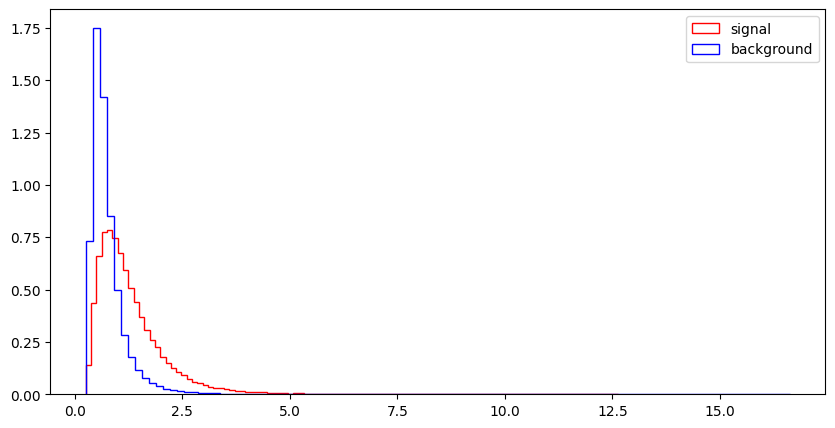

l_1_eta


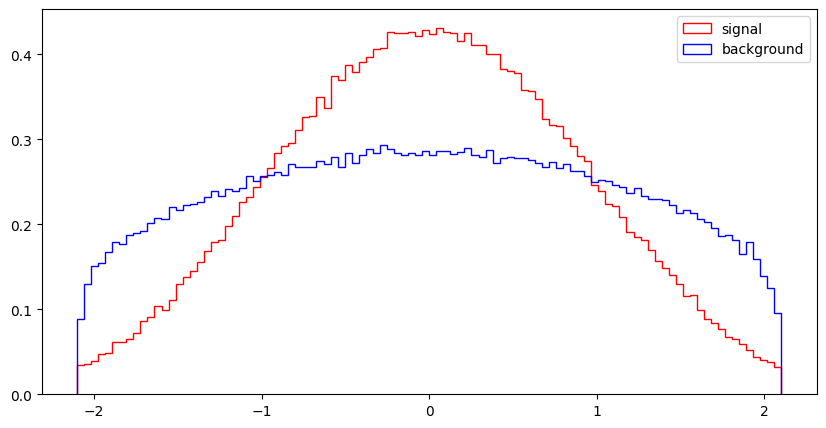

l_1_phi


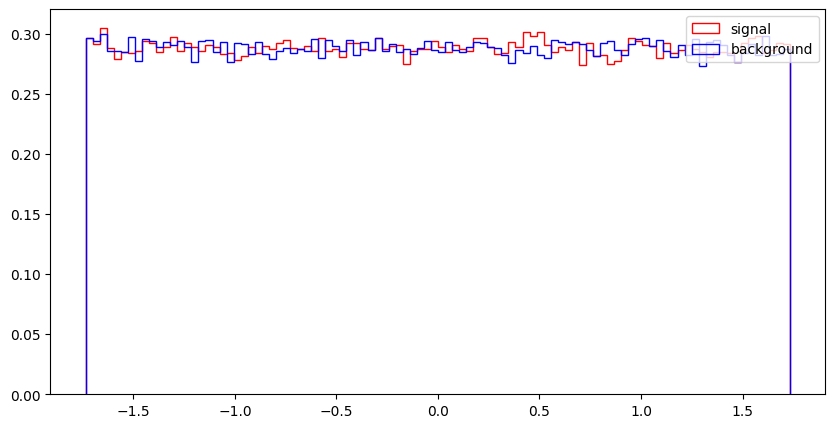

l_2_pT


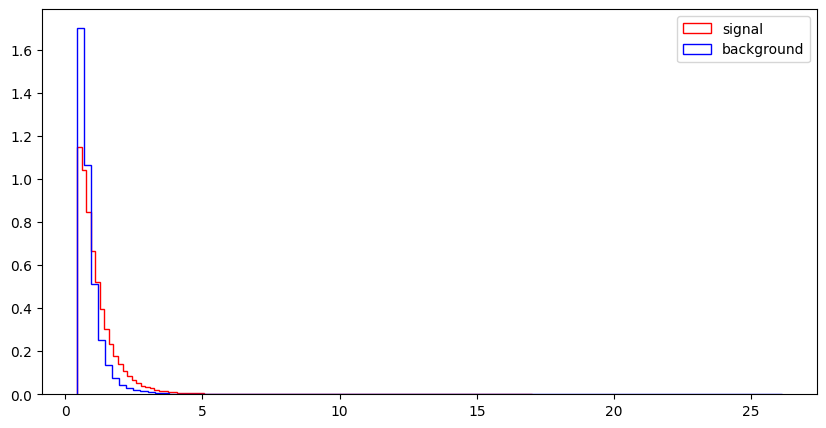

l_2_eta


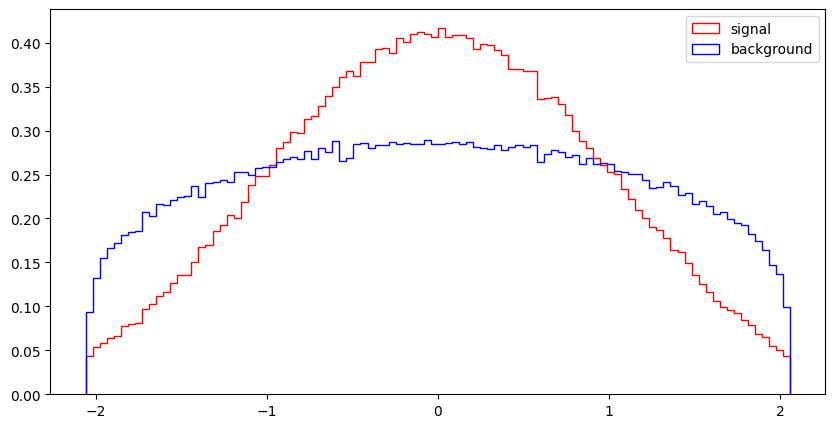

l_2_phi


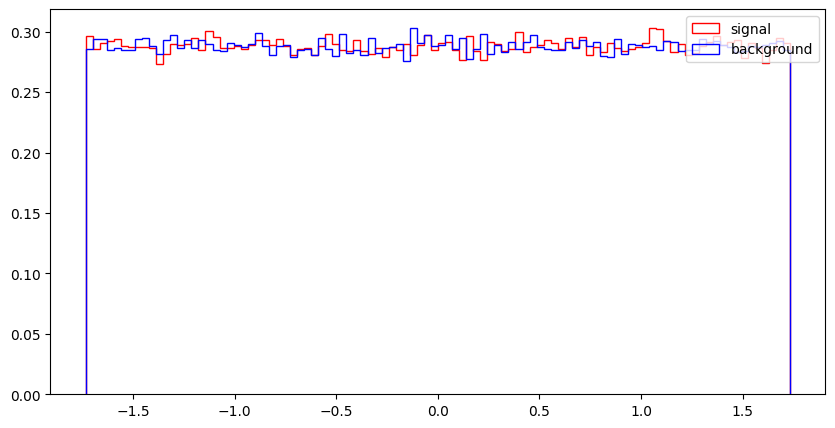

MET


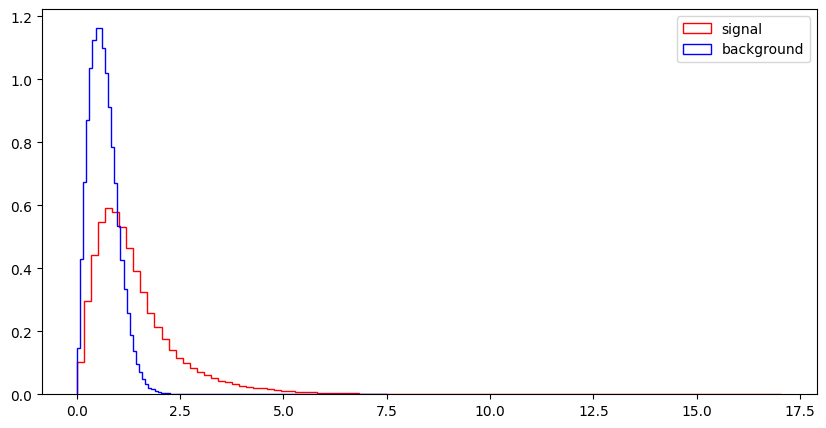

MET_phi


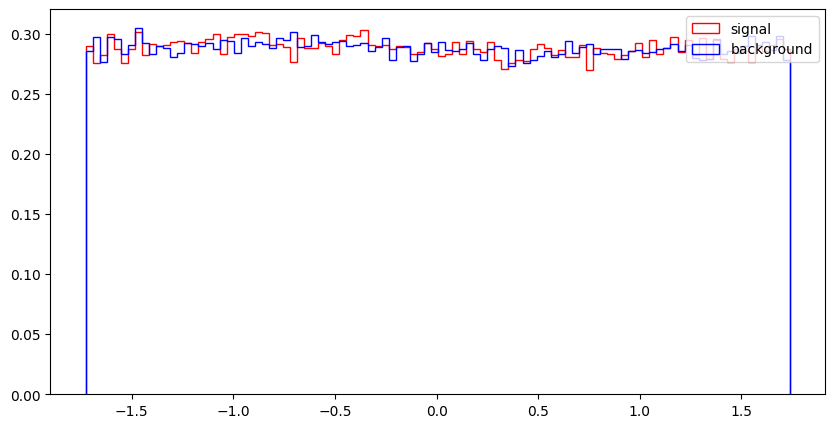

MET_rel


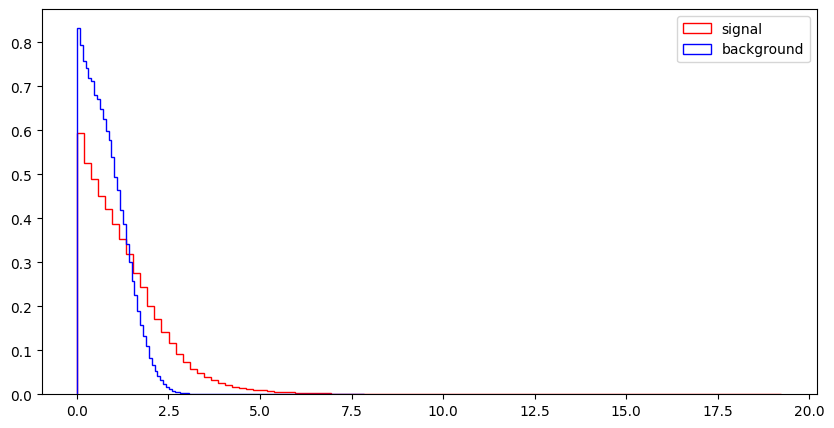

axial_MET


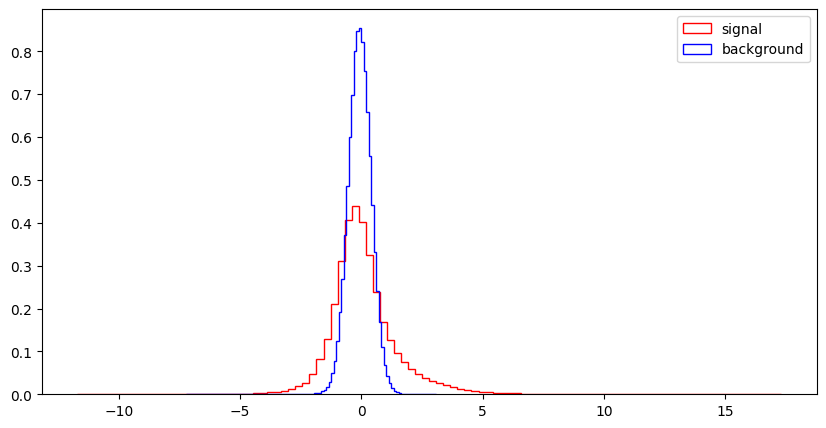

M_R


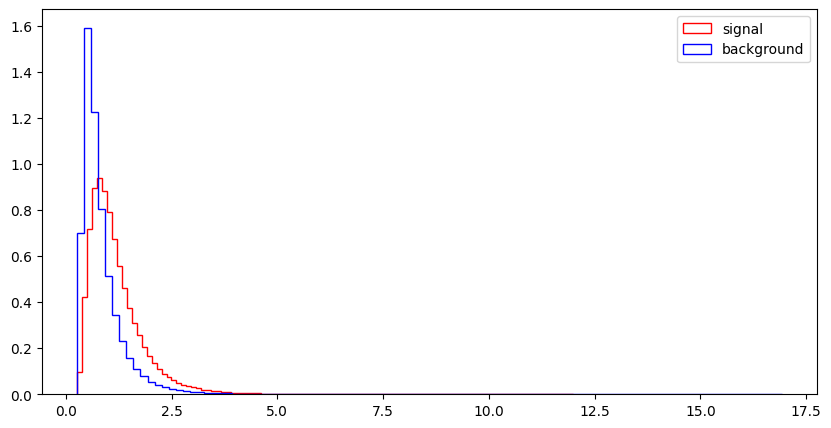

M_TR_2


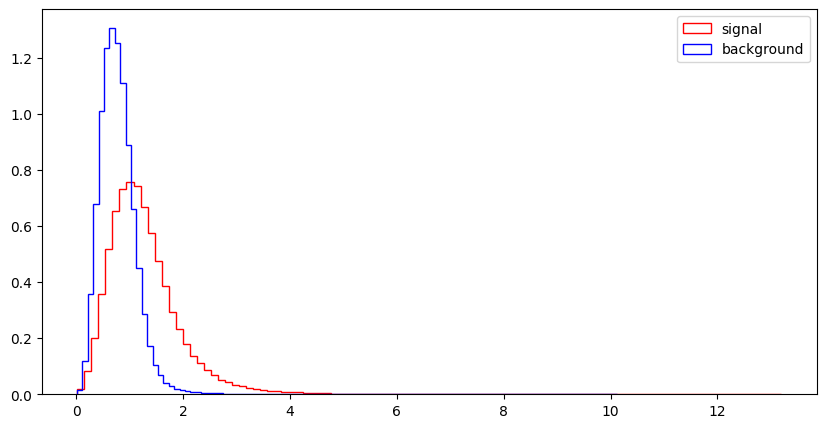

R


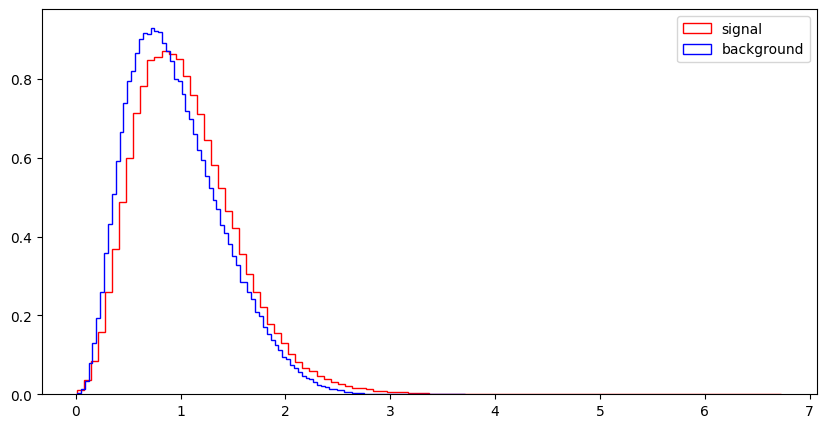

MT2


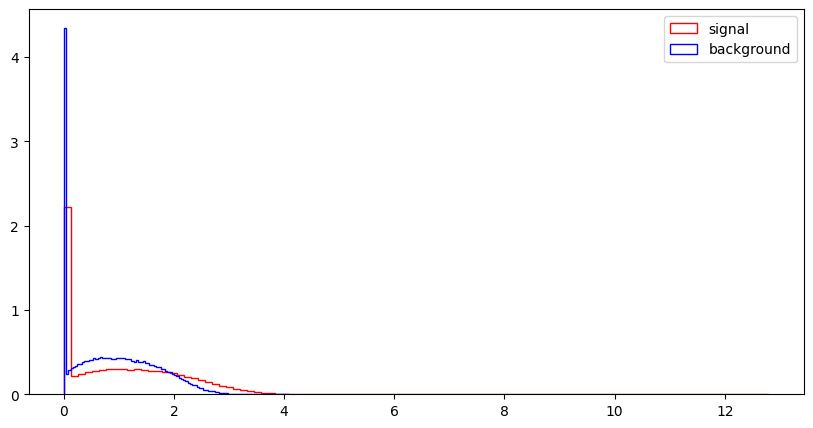

S_R


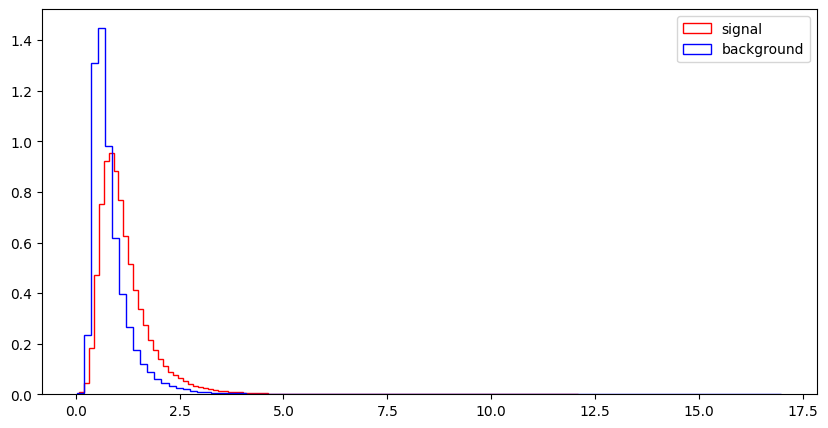

M_Delta_R


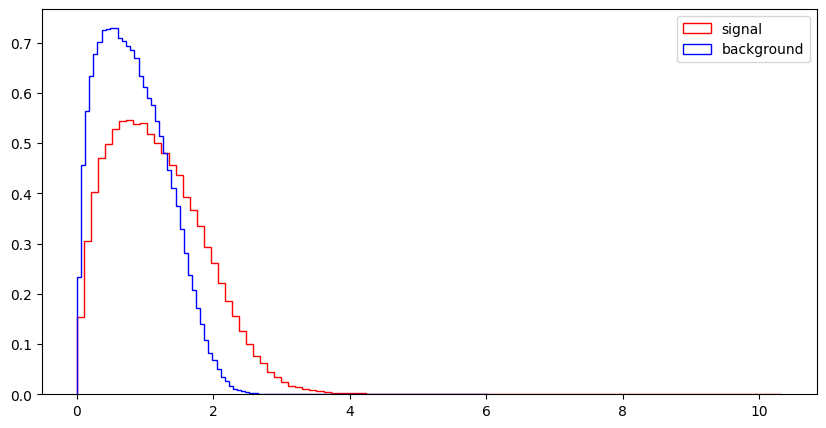

dPhi_r_b


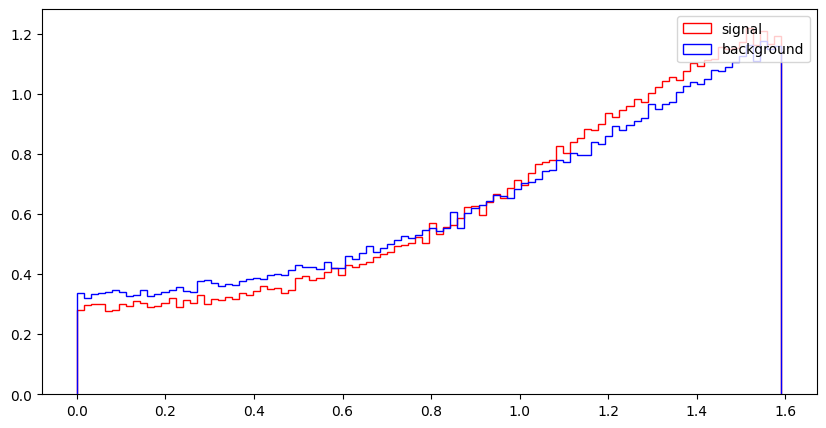

cos_theta_r1


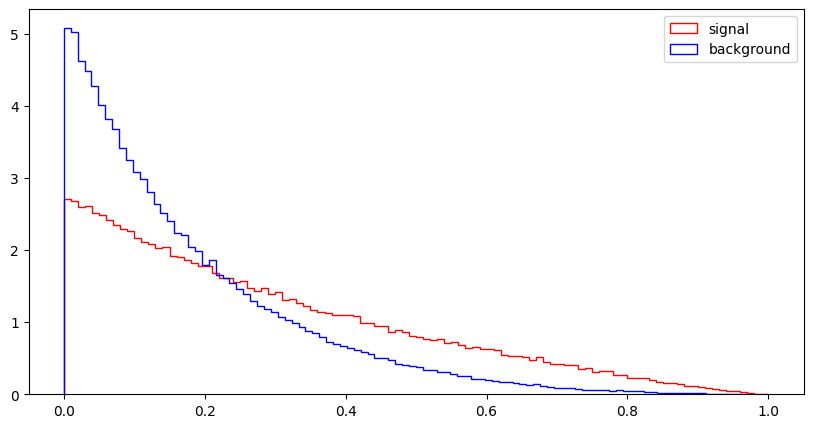

In [7]:
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()


## Exercise 3: Reproduce Figures 5 and 6 from the paper

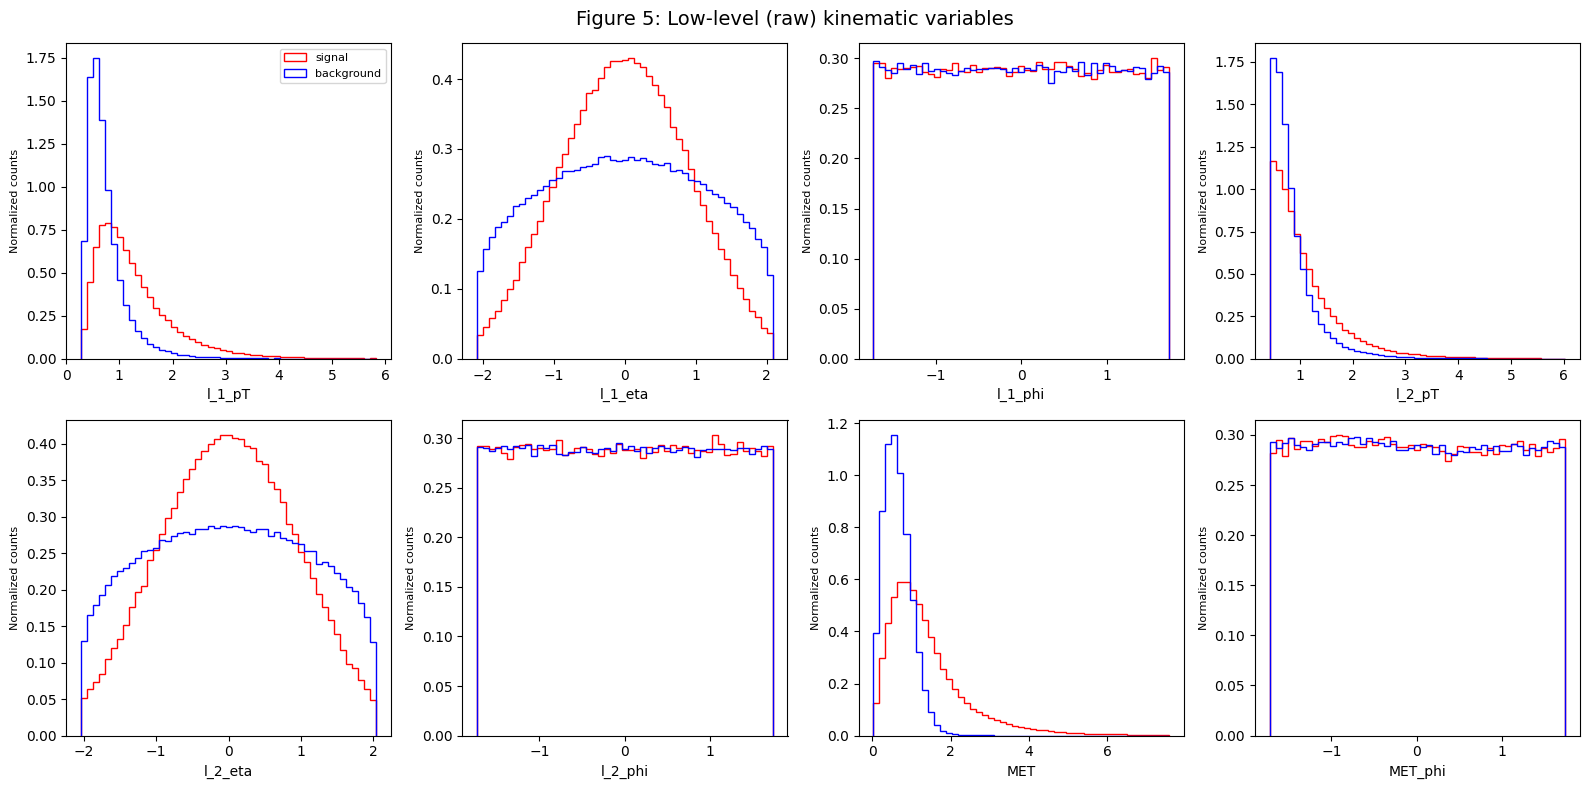

In [10]:
# Figure 5 style: raw kinematic variables
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(RawNames):
    ax = axes[i]
    # Get range for histogram
    data_all = pd.concat([df_sig[var], df_bkg[var]])
    bins = np.linspace(data_all.quantile(0.001), data_all.quantile(0.999), 50)
    
    ax.hist(np.array(df_sig[var]), bins=bins, histtype='step',
            color='red', label='signal', density=True)
    ax.hist(np.array(df_bkg[var]), bins=bins, histtype='step',
            color='blue', label='background', density=True)
    ax.set_xlabel(var, fontsize=10)
    ax.set_ylabel('Normalized counts', fontsize=8)
    if i == 0:
        ax.legend(fontsize=8)

fig.suptitle('Figure 5: Low-level (raw) kinematic variables', fontsize=14)
plt.tight_layout()
plt.show()

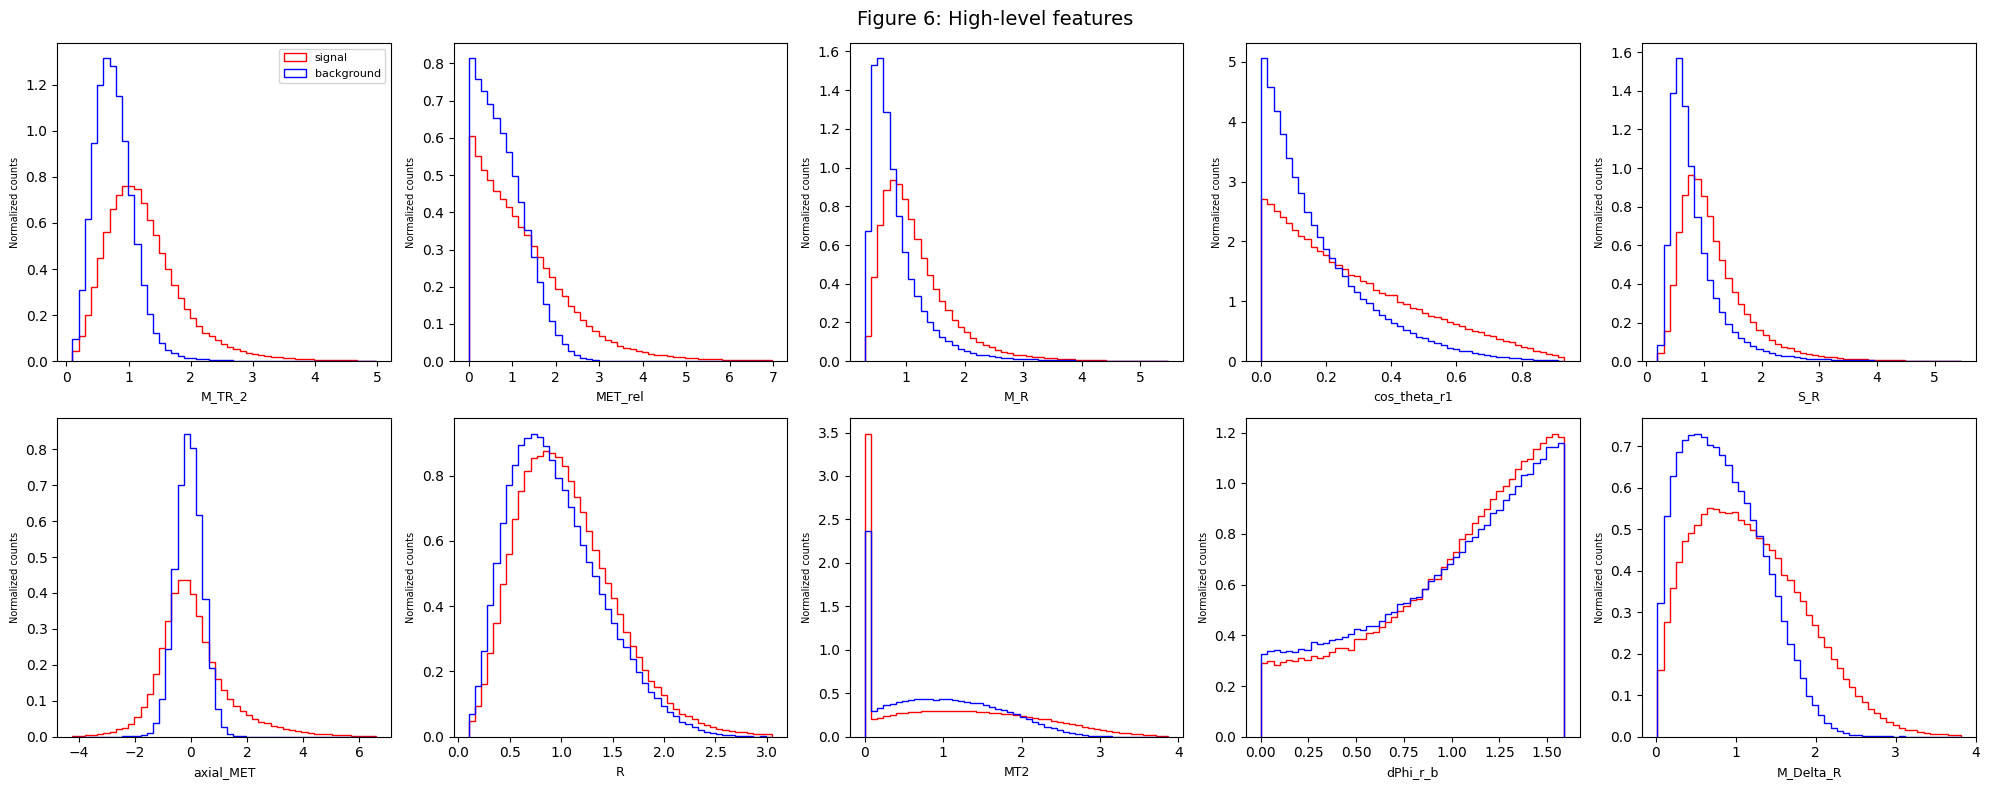

In [11]:
# Figure 6 style: high-level features
n_features = len(FeatureNames)
ncols = 5
nrows = (n_features + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 4 * nrows))
axes = axes.flatten()

for i, var in enumerate(FeatureNames):
    ax = axes[i]
    data_all = pd.concat([df_sig[var], df_bkg[var]])
    bins = np.linspace(data_all.quantile(0.001), data_all.quantile(0.999), 50)
    
    ax.hist(np.array(df_sig[var]), bins=bins, histtype='step',
            color='red', label='signal', density=True)
    ax.hist(np.array(df_bkg[var]), bins=bins, histtype='step',
            color='blue', label='background', density=True)
    ax.set_xlabel(var, fontsize=9)
    ax.set_ylabel('Normalized counts', fontsize=7)
    if i == 0:
        ax.legend(fontsize=8)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 6: High-level features', fontsize=14)
plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1: Pair Plots

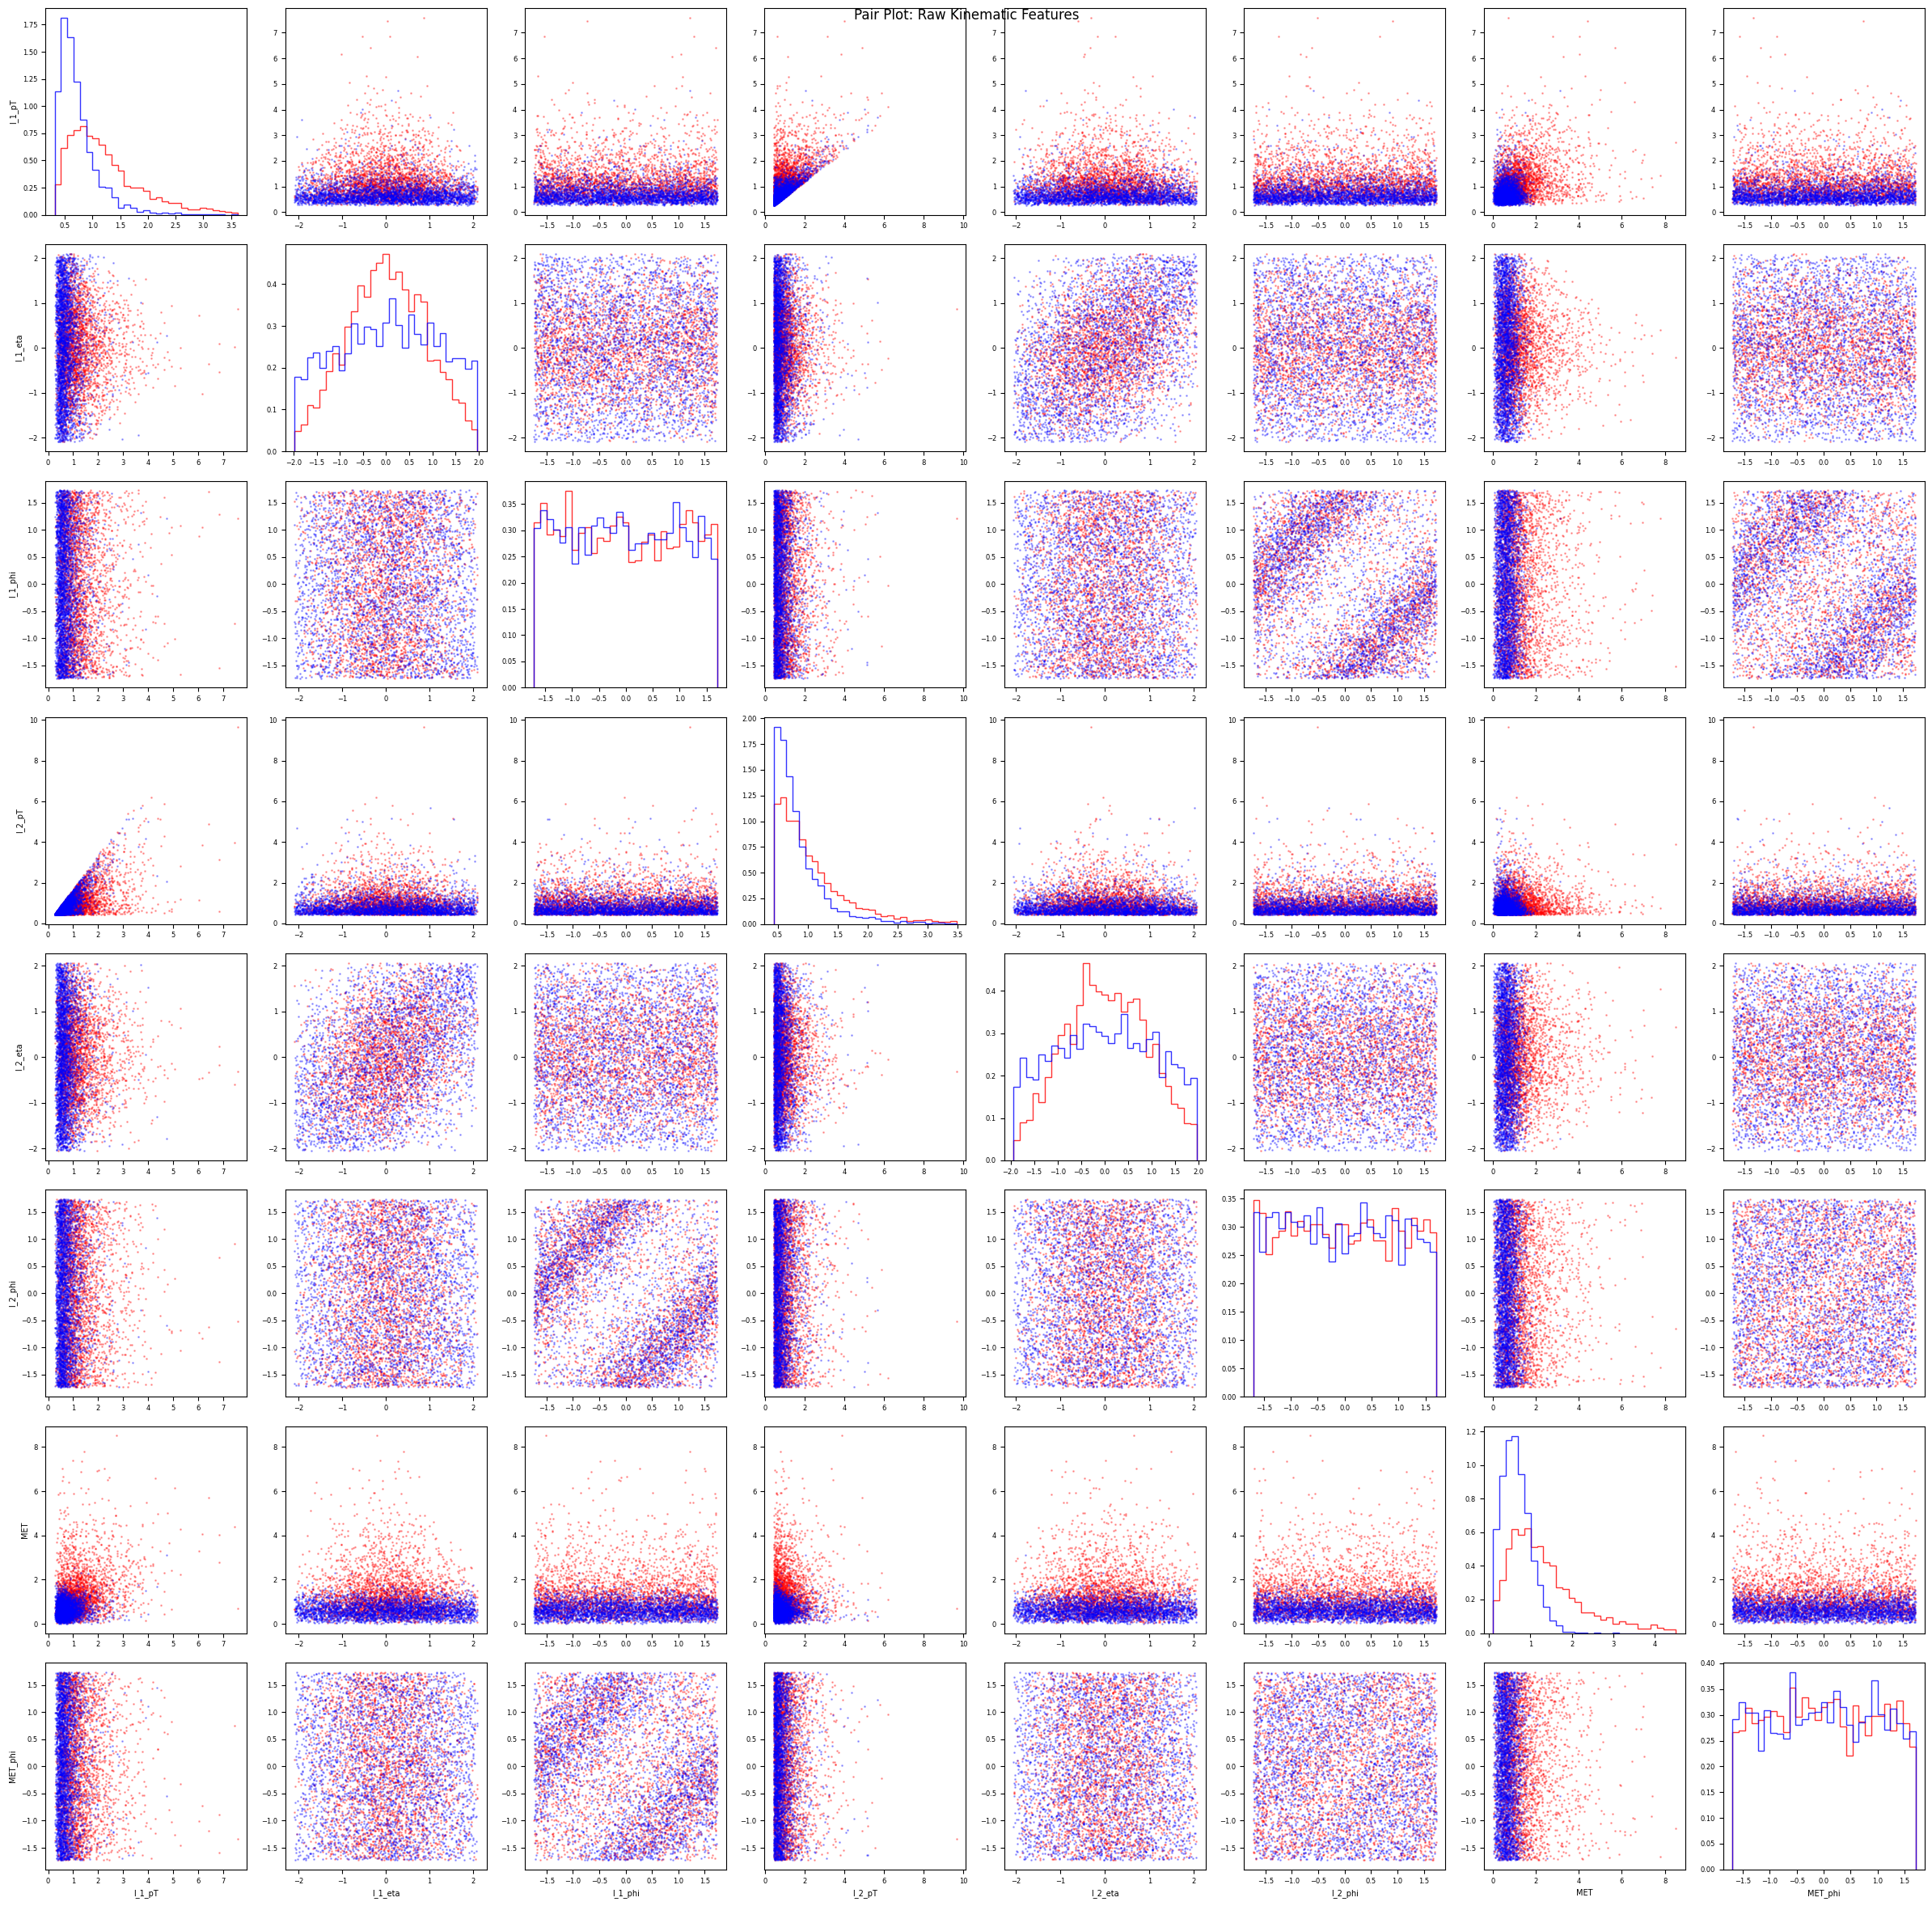

In [12]:
def make_pair_plot(df_s, df_b, var_list, sample_size=5000, nbins=30, title="Pair Plot"):
    """
    Create a pair plot comparing signal vs background distributions.
    
    Uses a random sample to speed things up, and pre-computes histograms
    for efficiency.
    """
    n = len(var_list)
    
    # Sample for speed
    s = df_s.sample(min(sample_size, len(df_s)), random_state=42)
    b = df_b.sample(min(sample_size, len(df_b)), random_state=42)
    
    fig, axes = plt.subplots(n, n, figsize=(3 * n, 3 * n))
    
    for i, var_i in enumerate(var_list):
        for j, var_j in enumerate(var_list):
            ax = axes[i][j]
            
            if i == j:
                # Diagonal: 1D histogram
                all_data = pd.concat([s[var_i], b[var_i]])
                bins = np.linspace(all_data.quantile(0.01), all_data.quantile(0.99), nbins)
                ax.hist(s[var_i], bins=bins, density=True, histtype='step', color='red', alpha=0.8)
                ax.hist(b[var_i], bins=bins, density=True, histtype='step', color='blue', alpha=0.8)
            else:
                # Off-diagonal: 2D scatter
                ax.scatter(s[var_j], s[var_i], s=1, c='red', alpha=0.3, label='signal')
                ax.scatter(b[var_j], b[var_i], s=1, c='blue', alpha=0.3, label='bkg')
            
            if i == n - 1:
                ax.set_xlabel(var_j, fontsize=7)
            if j == 0:
                ax.set_ylabel(var_i, fontsize=7)
            ax.tick_params(labelsize=6)
    
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

# Pair plot for low-level (raw) features
make_pair_plot(df_sig, df_bkg, RawNames, sample_size=3000, title="Pair Plot: Raw Kinematic Features")

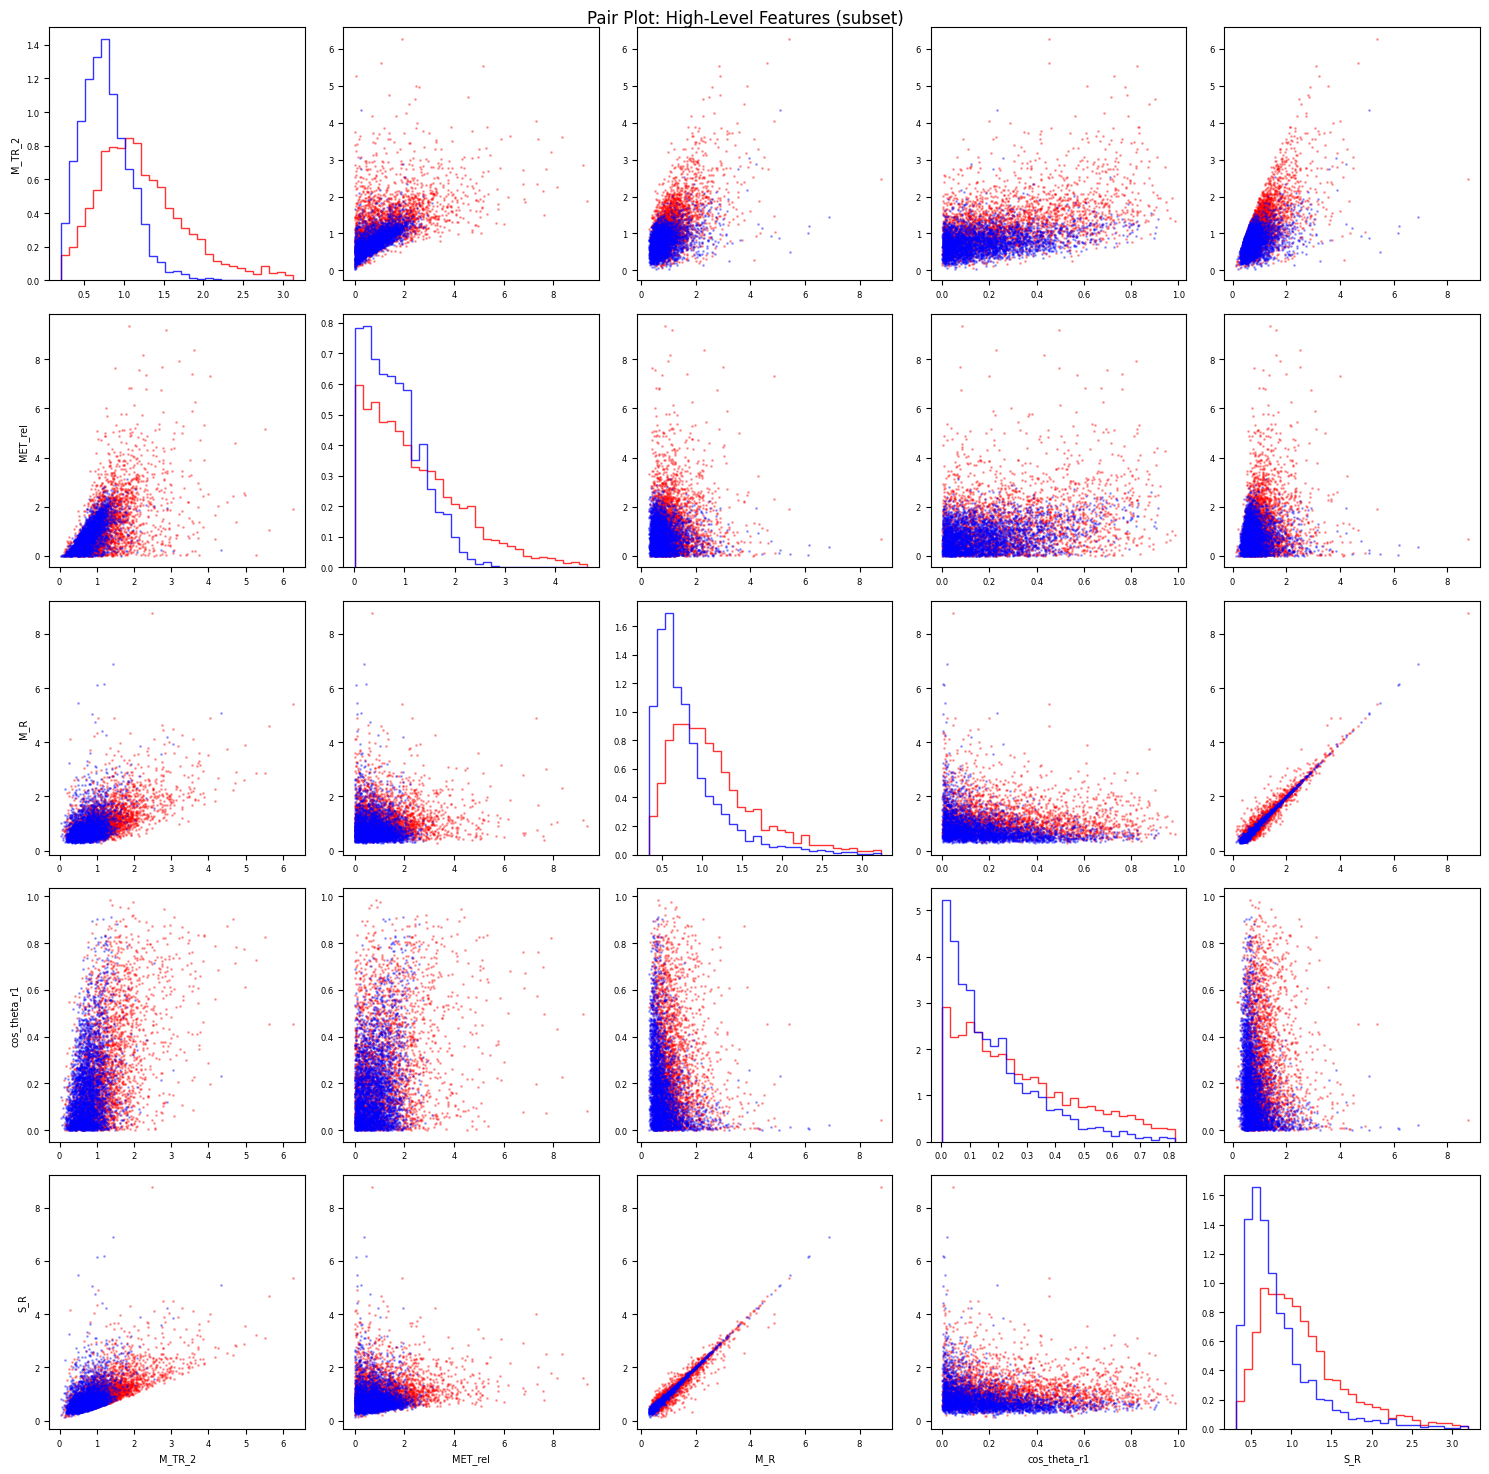

In [13]:
# Pair plot for high-level features (use a subset for readability)
# Using first 5 features to keep it manageable
make_pair_plot(df_sig, df_bkg, FeatureNames[:5], sample_size=3000, title="Pair Plot: High-Level Features (subset)")

### Exercise 4.1c: Best Observables for Separation

Looking at the 1D histograms (diagonal), the observables that show the clearest separation between signal (red) and background (blue) are:
- **M_Delta_R**: Good separation, signal peaks at higher values
- **S_R**: Clear separation  
- **R**: Reasonable separation
- **cos_theta_r1**: Some separation

Among raw variables, `MET` (missing transverse energy) shows the best separation.

### Exercise 4.2: Covariance and Correlation Matrices

In [17]:
!pip install tabulate


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [19]:
from IPython.display import HTML, display
import tabulate
import numpy as np

def compute_and_display_matrices(data, var_names, label="Dataset"):
    """
    Compute covariance and correlation matrices for given variables
    and display them as formatted HTML tables.
    """
    X = np.array(data[var_names])
    
    cov_matrix = np.cov(X.T)
    corr_matrix = np.corrcoef(X.T)
    
    # Format for display - round to 3 significant figures
    def format_matrix(mat, names):
        rows = []
        for i, name in enumerate(names):
            row = [name] + [f"{mat[i, j]:.3g}" for j in range(len(names))]
            rows.append(row)
        return rows
    
    headers = [""] + var_names
    
    print(f"\n {label}: Covariance Matrix ")
    display(HTML(tabulate.tabulate(format_matrix(cov_matrix, var_names),
                                   tablefmt='html', headers=headers)))
    
    print(f"\n {label}: Correlation Matrix")
    display(HTML(tabulate.tabulate(format_matrix(corr_matrix, var_names),
                                   tablefmt='html', headers=headers)))
    
    return cov_matrix, corr_matrix

# Part B Executions:

# All observables (excluding 'signal')
cov_all, corr_all = compute_and_display_matrices(df, VarNames[1:], label="All Variables (signal+background)")

# Low-level features
cov_low, corr_low = compute_and_display_matrices(df, RawNames, label="Low-Level Features")

# High-level features
cov_high, corr_high = compute_and_display_matrices(df, FeatureNames, label="High-Level Features")


 All Variables (signal+background): Covariance Matrix 


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537



 All Variables (signal+background): Correlation Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137,0.16,-0.0142,0.851,0.723,-0.186,-0.0211,0.811,0.229,-0.157,0.165
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587,-0.00154,-0.0011,-0.000882,-0.00115,0.000639,0.000496,-0.000975,-0.00158,-0.00169,0.00163
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184,0.000793,-0.00186,0.00169,0.00149,0.000427,0.00123,0.00236,0.00144,0.00228,0.00131
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239,-0.000921,0.0785,0.797,0.43,-0.324,-0.123,0.799,0.0141,-0.0135,-0.217
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321,0.00122,-0.000752,-0.000967,3.24e-05,0.000679,0.00162,-0.00109,0.00107,-0.000701,0.0015
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353,0.00162,-0.00179,0.00121,0.000874,0.00117,0.00263,0.00146,0.00212,-0.000552,0.000188
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1,-0.0055,-0.00044,-0.00236,-0.00206,-0.000487,9.75e-05,-0.00276,-0.000913,-0.00391,0.000605
MET_rel,0.16,-0.00154,0.000793,-0.000921,0.00122,0.00162,0.704,-0.0055,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.0142,-0.0011,-0.00186,0.0785,-0.000752,-0.00179,0.176,-0.00044,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272



 Low-Level Features: Covariance Matrix 


...

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1



 High-Level Features: Covariance Matrix 


,M_TR_2,MET_rel,M_R,cos_theta_r1,S_R,axial_MET,R,MT2,dPhi_r_b,M_Delta_R
M_TR_2,0.338,0.302,0.21,0.0517,0.228,-0.185,0.104,0.189,0.0581,0.242
MET_rel,0.302,0.79,0.0437,0.0553,0.0823,-0.12,0.249,0.409,0.146,0.415
M_R,0.21,0.0437,0.392,-0.0143,0.38,0.0171,-0.113,-0.0365,-0.029,0.0739
cos_theta_r1,0.0517,0.0553,-0.0143,0.0388,-0.0104,-0.0537,0.0582,0.0446,0.00908,0.0392
S_R,0.228,0.0823,0.38,-0.0104,0.382,-0.0414,-0.0834,-0.011,-0.00346,0.0958
axial_MET,-0.185,-0.12,0.0171,-0.0537,-0.0414,1.01,-0.181,-0.461,-0.0251,-0.233
R,0.104,0.249,-0.113,0.0582,-0.0834,-0.181,0.222,0.232,0.0871,0.165
MT2,0.189,0.409,-0.0365,0.0446,-0.011,-0.461,0.232,0.738,0.0209,0.433
dPhi_r_b,0.0581,0.146,-0.029,0.00908,-0.00346,-0.0251,0.0871,0.0209,0.19,0.0422
M_Delta_R,0.242,0.415,0.0739,0.0392,0.0958,-0.233,0.165,0.433,0.0422,0.389



 High-Level Features: Correlation Matrix


,M_TR_2,MET_rel,M_R,cos_theta_r1,S_R,axial_MET,R,MT2,dPhi_r_b,M_Delta_R
M_TR_2,1,0.584,0.577,0.451,0.635,-0.317,0.38,0.379,0.229,0.668
MET_rel,0.584,1,0.0785,0.316,0.15,-0.134,0.595,0.535,0.378,0.748
M_R,0.577,0.0785,1,-0.116,0.981,0.0273,-0.383,-0.0679,-0.106,0.189
cos_theta_r1,0.451,0.316,-0.116,1,-0.0851,-0.272,0.627,0.264,0.106,0.319
S_R,0.635,0.15,0.981,-0.0851,1,-0.0668,-0.287,-0.0208,-0.0128,0.249
axial_MET,-0.317,-0.134,0.0273,-0.272,-0.0668,1,-0.383,-0.535,-0.0574,-0.373
R,0.38,0.595,-0.383,0.627,-0.287,-0.383,1,0.574,0.424,0.564
MT2,0.379,0.535,-0.0679,0.264,-0.0208,-0.535,0.574,1,0.0558,0.809
dPhi_r_b,0.229,0.378,-0.106,0.106,-0.0128,-0.0574,0.424,0.0558,1,0.155
M_Delta_R,0.668,0.748,0.189,0.319,0.249,-0.373,0.564,0.809,0.155,1


In [ ]:
# Low-level (raw) features only
cov_raw, corr_raw = compute_and_display_matrices(df, RawNames, label="Raw Features")

In [ ]:
# High-level features only
cov_feat, corr_feat = compute_and_display_matrices(df, FeatureNames, label="High-Level Features")

## Exercise 5: Selection

### Exercise 5.1: Selection Strategy

From the distributions, we determine:
- **M_Delta_R**: signal peaks at higher values - `x > x_c` (strategy 1)
- **S_R**: signal peaks at lower values - `x < x_c` (strategy 2)  
- **R**: signal peaks at higher values - `x > x_c` (strategy 1)
- **MET_rel**: signal peaks at higher values - `x > x_c` (strategy 1)
- **cos_theta_r1**: signal peaks at higher values - `x > x_c` (strategy 1)

In [21]:
# Define selection strategies for each variable
# 'gt': x > x_c (signal at high values)
# 'lt': x < x_c (signal at low values)
selection_strategy = {
    "l_1_pT": "gt",
    "l_1_eta": "abs_lt",  # |x - 0| < x_c
    "l_1_phi": "abs_lt",
    "l_2_pT": "gt",
    "l_2_eta": "abs_lt",
    "l_2_phi": "abs_lt",
    "MET": "gt",
    "MET_phi": "abs_lt",
    "MET_rel": "gt",
    "axial_MET": "gt",
    "M_R": "gt",
    "M_TR_2": "gt",
    "R": "gt",
    "MT2": "gt",
    "S_R": "lt",
    "M_Delta_R": "gt",
    "dPhi_r_b": "gt",
    "cos_theta_r1": "gt",
}

print("Selection strategies defined for", len(selection_strategy), "variables")

Selection strategies defined for 18 variables


In [20]:
def compute_efficiencies(sig_vals, bkg_vals, strategy, n_cuts=100):
    """
    Compute signal and background efficiencies as a function of cut value.
    Returns (cut_values, TPR, FPR)
    """
    all_vals = np.concatenate([sig_vals, bkg_vals])
    cut_vals = np.linspace(np.percentile(all_vals, 1), np.percentile(all_vals, 99), n_cuts)
    
    tpr = []
    fpr = []
    
    for xc in cut_vals:
        if strategy == "gt":
            tpr.append(np.sum(sig_vals > xc) / len(sig_vals))
            fpr.append(np.sum(bkg_vals > xc) / len(bkg_vals))
        elif strategy == "lt":
            tpr.append(np.sum(sig_vals < xc) / len(sig_vals))
            fpr.append(np.sum(bkg_vals < xc) / len(bkg_vals))
        elif strategy == "abs_lt":
            mu_sig = np.mean(sig_vals)
            tpr.append(np.sum(np.abs(sig_vals - mu_sig) < xc) / len(sig_vals))
            fpr.append(np.sum(np.abs(bkg_vals - mu_sig) < xc) / len(bkg_vals))
        elif strategy == "abs_gt":
            mu_sig = np.mean(sig_vals)
            tpr.append(np.sum(np.abs(sig_vals - mu_sig) > xc) / len(sig_vals))
            fpr.append(np.sum(np.abs(bkg_vals - mu_sig) > xc) / len(bkg_vals))
    
    return np.array(cut_vals), np.array(tpr), np.array(fpr)

print("Efficiency function defined")

Efficiency function defined


### Exercise 5.2: TPR and FPR vs Cut Value

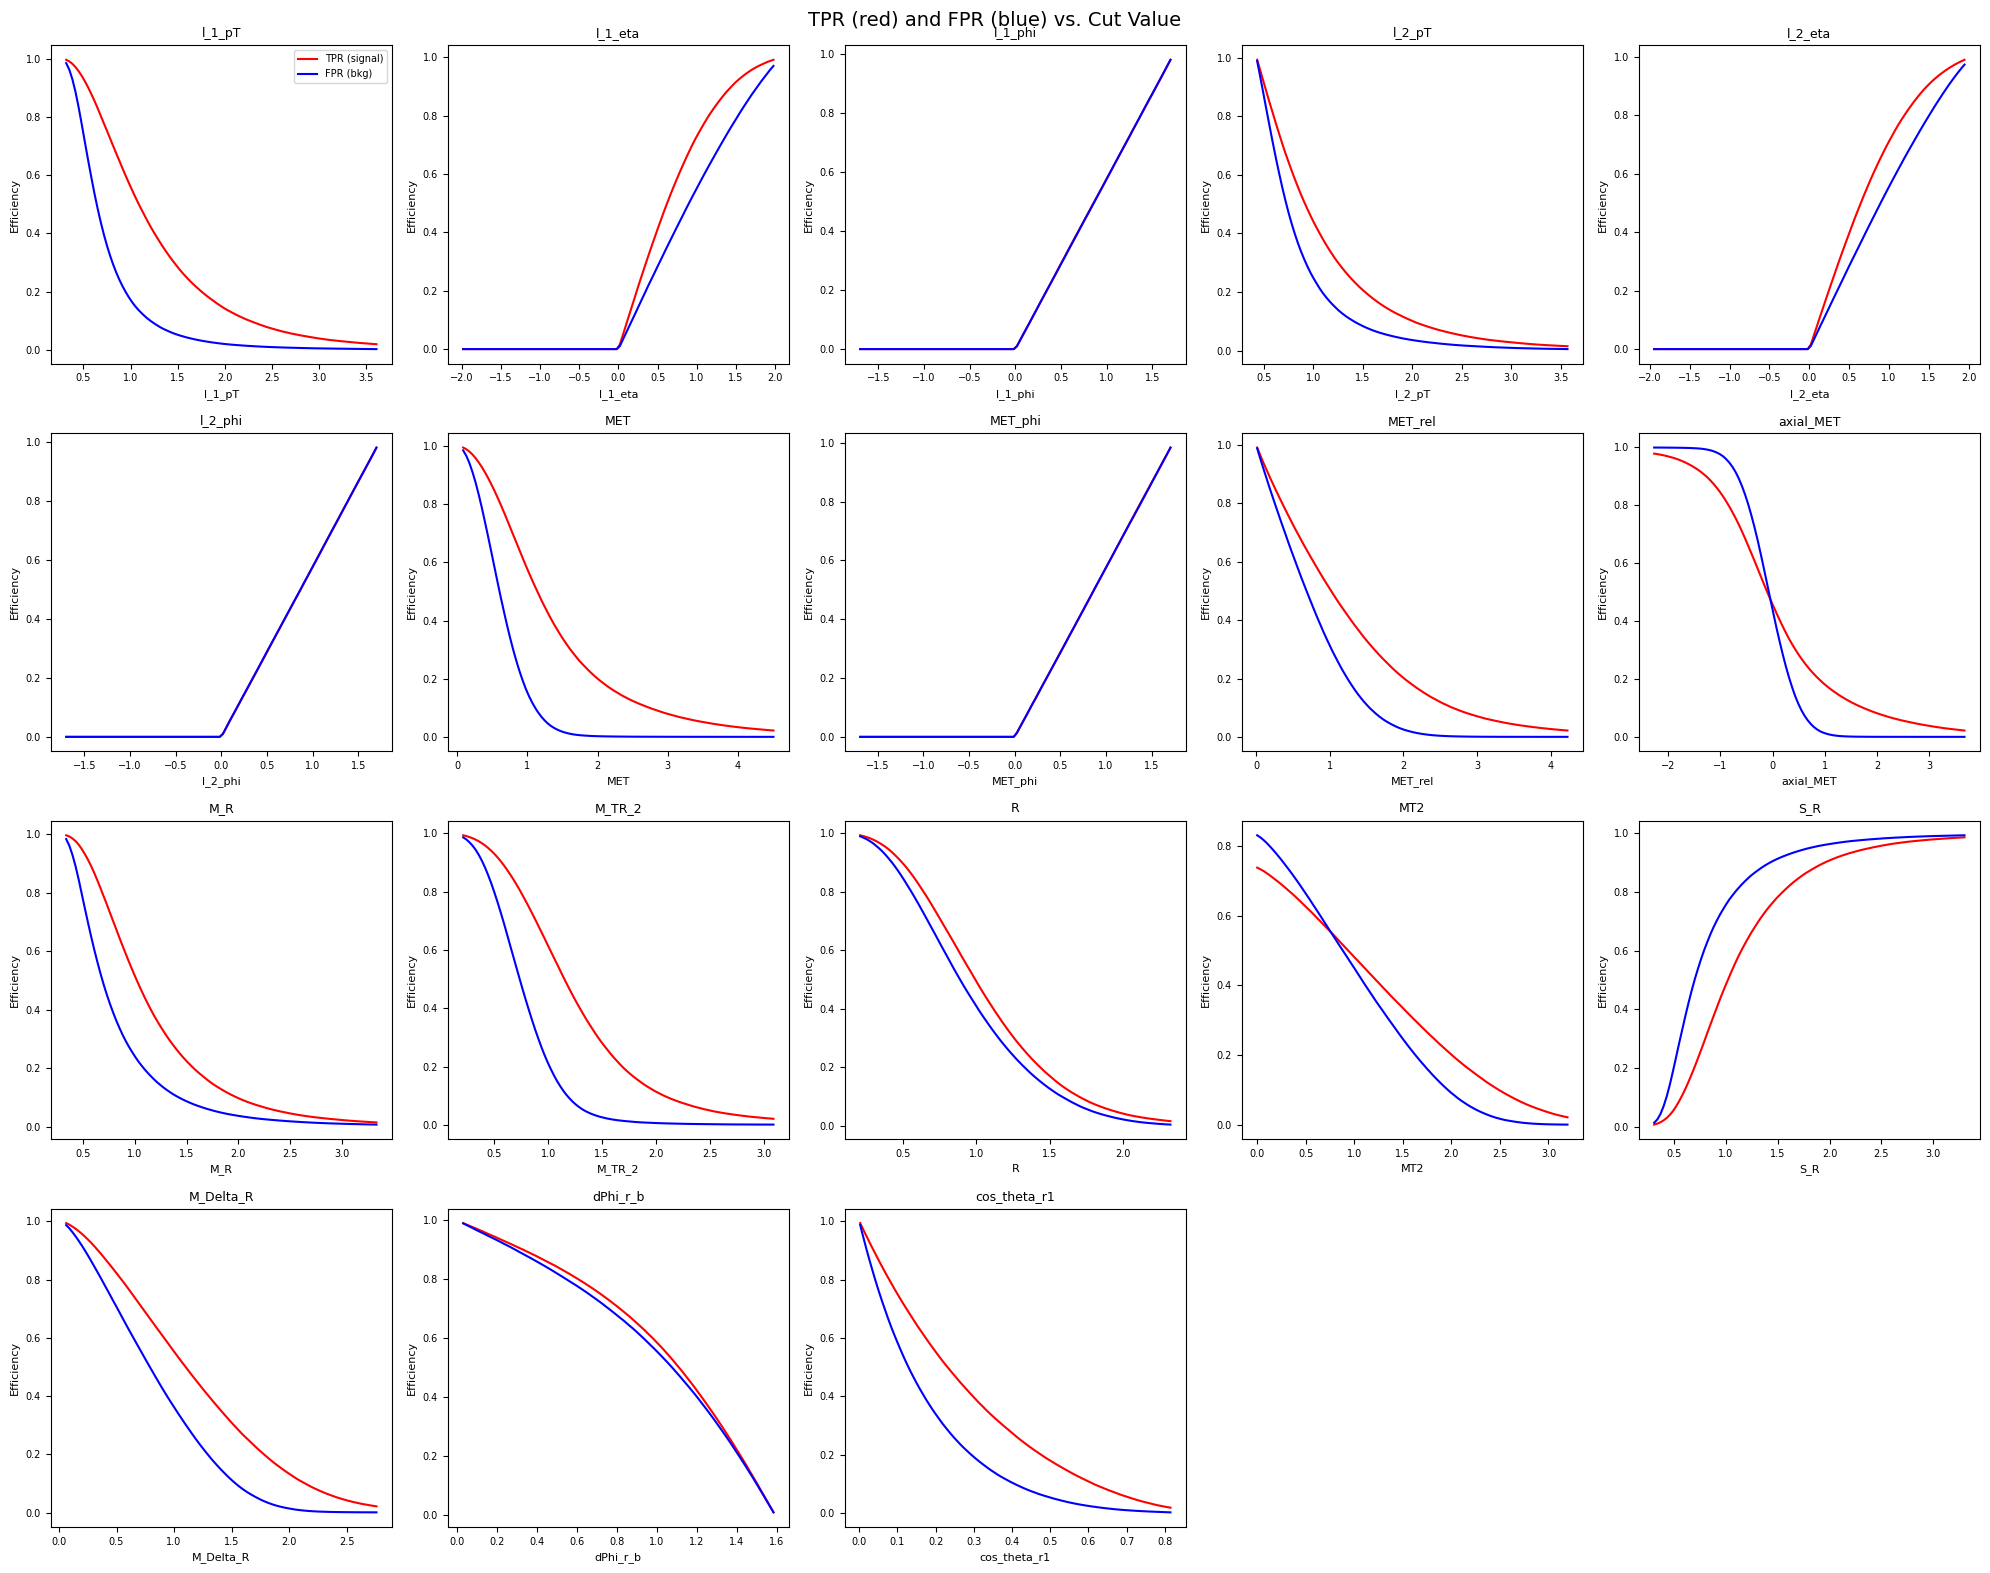

In [23]:
# TPR and FPR for each variable
vars_to_plot = VarNames[1:]  # all variables except 'signal'

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
axes = axes.flatten()

for i, var in enumerate(vars_to_plot[:20]):
    if i >= len(axes):
        break
    ax = axes[i]
    strategy = selection_strategy.get(var, "gt")
    
    cut_vals, tpr, fpr = compute_efficiencies(
        np.array(df_sig[var]),
        np.array(df_bkg[var]),
        strategy
    )
    
    ax.plot(cut_vals, tpr, 'r-', label='TPR (signal)', linewidth=1.5)
    ax.plot(cut_vals, fpr, 'b-', label='FPR (bkg)', linewidth=1.5)
    ax.set_xlabel(f'{var}', fontsize=8)
    ax.set_ylabel('Efficiency', fontsize=8)
    ax.set_title(var, fontsize=9)
    ax.tick_params(labelsize=7)
    if i == 0:
        ax.legend(fontsize=7)

# Hide unused subplots
for j in range(len(vars_to_plot), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('TPR (red) and FPR (blue) vs. Cut Value', fontsize=14)
plt.tight_layout()
plt.show()

### Exercise 5.3: Significance vs Cut Value

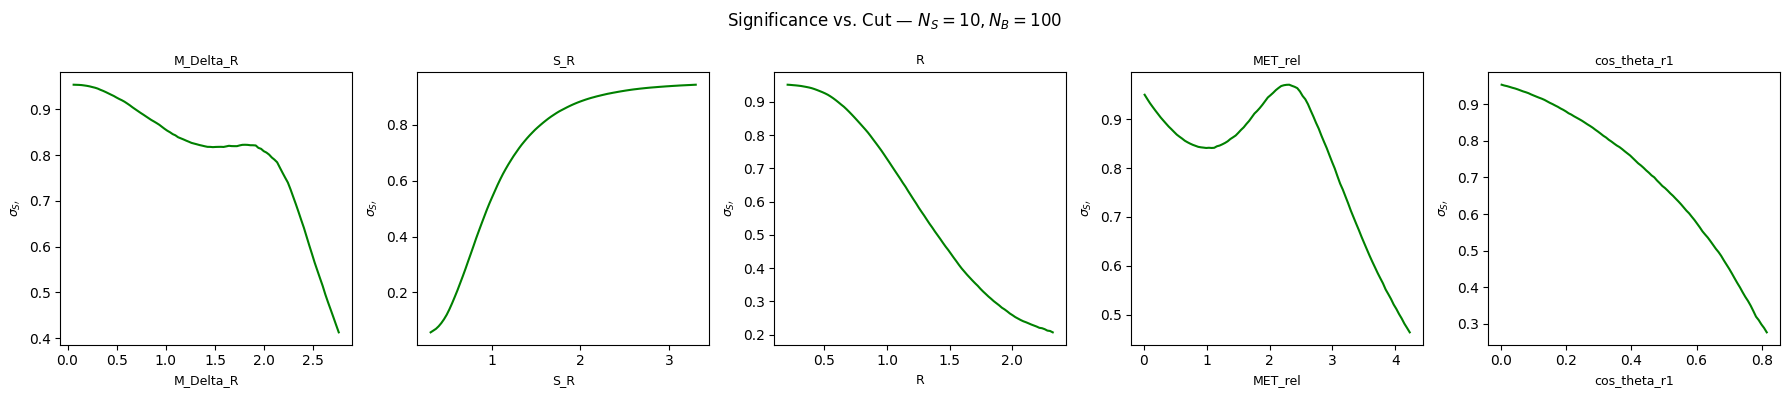

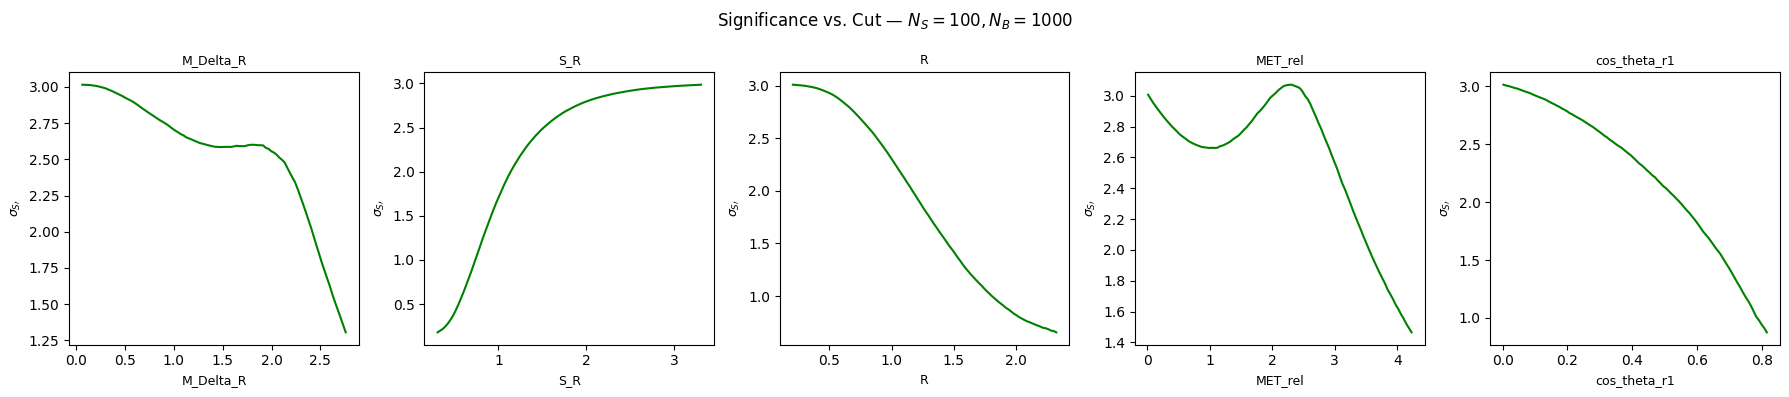

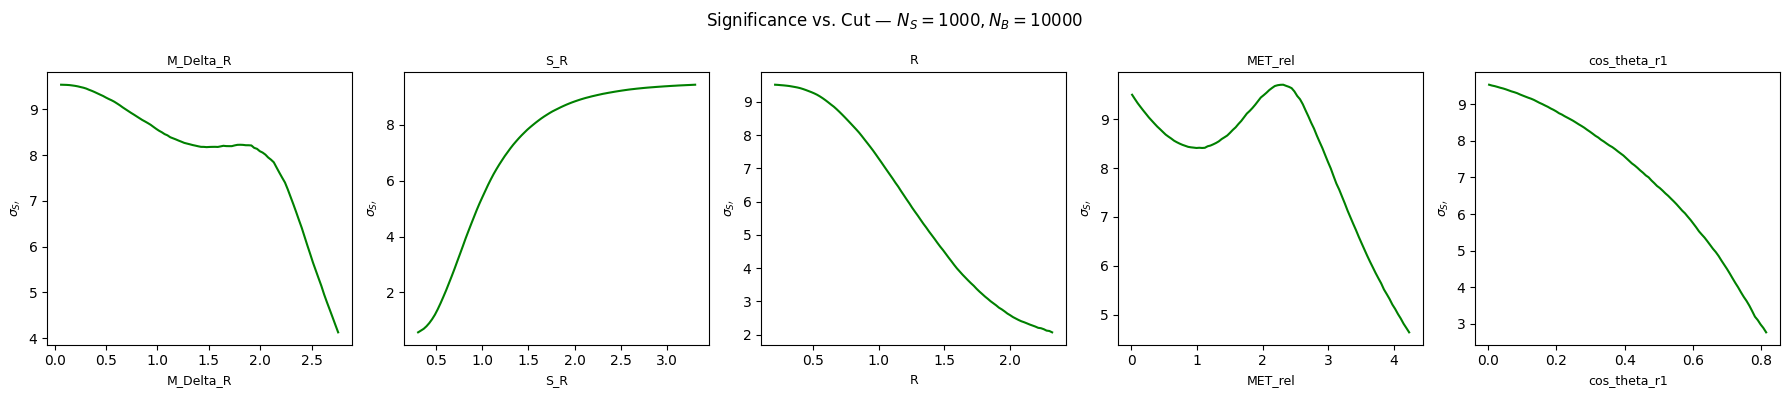

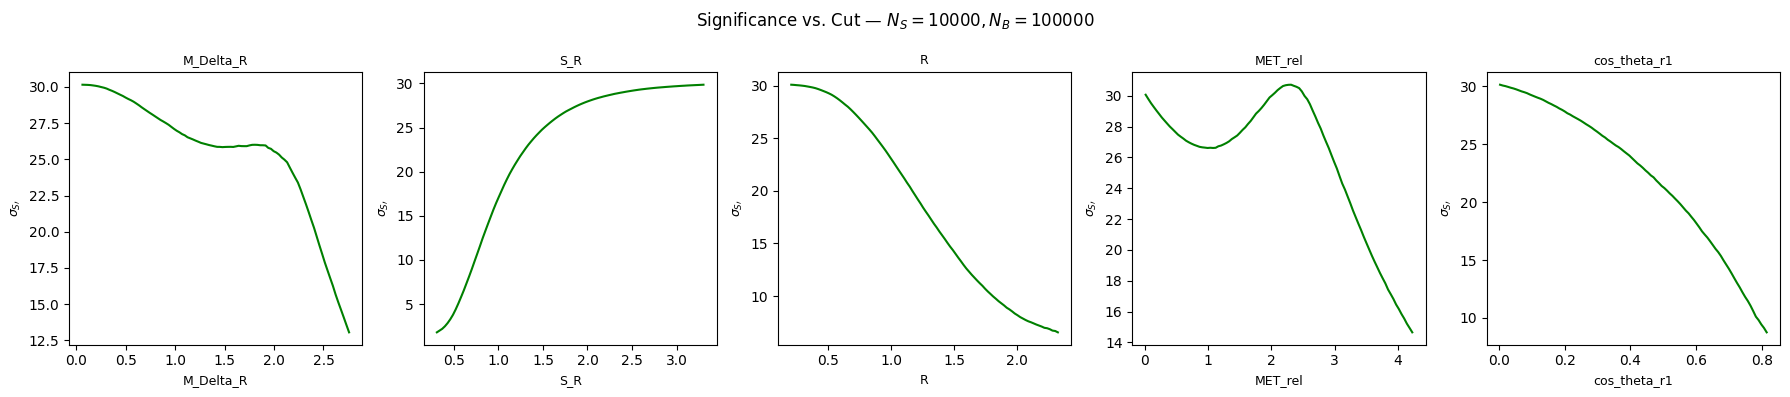

In [25]:
def significance(tpr, fpr, NS, NB):
    """ significance sigma_S' = NS' / sqrt(NS' + NB')"""
    NS_prime = tpr * NS
    NB_prime = fpr * NB
    denom = np.sqrt(NS_prime + NB_prime)
    # Avoiding division by zero
    with np.errstate(divide='ignore', invalid='ignore'):
        sig = np.where(denom > 0, NS_prime / denom, 0)
    return sig

# Four scenarios
scenarios = [
    (10, 100, "$N_S=10, N_B=100$"),
    (100, 1000, "$N_S=100, N_B=1000$"),
    (1000, 10000, "$N_S=1000, N_B=10000$"),
    (10000, 100000, "$N_S=10000, N_B=100000$"),
]

# Pick a few interesting variables to display
selected_vars = ["M_Delta_R", "S_R", "R", "MET_rel", "cos_theta_r1"]

for NS, NB, label in scenarios:
    fig, axes = plt.subplots(1, len(selected_vars), figsize=(18, 4))
    
    for ax, var in zip(axes, selected_vars):
        strategy = selection_strategy.get(var, "gt")
        cut_vals, tpr, fpr = compute_efficiencies(
            np.array(df_sig[var]),
            np.array(df_bkg[var]),
            strategy
        )
        sig = significance(tpr, fpr, NS, NB)
        ax.plot(cut_vals, sig, 'g-', linewidth=1.5)
        ax.set_xlabel(var, fontsize=9)
        ax.set_ylabel(r'$\sigma_{S\prime}$', fontsize=9)
        ax.set_title(f'{var}', fontsize=9)
    
    fig.suptitle(f'Significance vs. Cut — {label}', fontsize=12)
    plt.tight_layout()
    plt.show()

## Exercise 6: Cut Flow

In [27]:

# approximate optimal cuts from the significance plots
cuts = [
    ("M_Delta_R", "gt", 0.5),
    ("S_R",       "lt", 2.0),
    ("R",         "gt", 0.5),
]

def apply_cut(data, var, strategy, xc):
    """Return mask for events passing the cut."""
    if strategy == "gt":
        return data[var] > xc
    elif strategy == "lt":
        return data[var] < xc
    elif strategy == "abs_lt":
        mu = data[var].mean()
        return np.abs(data[var] - mu) < xc
    elif strategy == "abs_gt":
        mu = data[var].mean()
        return np.abs(data[var] - mu) > xc


def cut_flow_table(df_s, df_b, cut_list, NS, NB):
    """
    Build a cut-flow table. Returns list of rows:
    [cut_label, eps_S, eps_B, NS', NB', sigma_S']
    """
    N_s_total = len(df_s)
    N_b_total = len(df_b)
    
    current_sig = df_s.copy()
    current_bkg = df_b.copy()
    
    rows = []
    
    # No cut baseline
    eps_s = len(current_sig) / N_s_total
    eps_b = len(current_bkg) / N_b_total
    NS_prime = eps_s * NS
    NB_prime = eps_b * NB
    denom = np.sqrt(NS_prime + NB_prime)
    sig = NS_prime / denom if denom > 0 else 0
    rows.append(["No cut", f"{eps_s:.3f}", f"{eps_b:.3f}",
                 f"{NS_prime:.1f}", f"{NB_prime:.1f}", f"{sig:.3f}"])
    
    for var, strategy, xc in cut_list:
        mask_s = apply_cut(current_sig, var, strategy, xc)
        mask_b = apply_cut(current_bkg, var, strategy, xc)
        current_sig = current_sig[mask_s]
        current_bkg = current_bkg[mask_b]
        
        eps_s = len(current_sig) / N_s_total
        eps_b = len(current_bkg) / N_b_total
        NS_prime = eps_s * NS
        NB_prime = eps_b * NB
        denom = np.sqrt(NS_prime + NB_prime)
        sig = NS_prime / denom if denom > 0 else 0
        
        label = f"{var} {strategy} {xc}"
        rows.append([label, f"{eps_s:.3f}", f"{eps_b:.3f}",
                     f"{NS_prime:.1f}", f"{NB_prime:.1f}", f"{sig:.3f}"])
    
    return rows


headers = ["Cut", "eps_S", "eps_B", "N'_S", "N'_B", "sigma_S'"]

for NS, NB, label in scenarios:
    print(f"\n{'='*60}")
    print(f"Scenario: {label}")
    print('='*60)
    rows = cut_flow_table(df_sig, df_bkg, cuts, NS, NB)
    display(HTML(tabulate.tabulate(rows, tablefmt='html', headers=headers)))


Scenario: $N_S=10, N_B=100$


Cut,eps_S,eps_B,N'_S,N'_B,sigma_S'
No cut,1,1,10,100,0.953
M_Delta_R gt 0.5,0.822,0.706,8.2,70.6,0.925
S_R lt 2.0,0.74,0.678,7.4,67.8,0.854
R gt 0.5,0.703,0.637,7,63.7,0.835



Scenario: $N_S=100, N_B=1000$


Cut,eps_S,eps_B,N'_S,N'_B,sigma_S'
No cut,1,1,100,1000,3.015
M_Delta_R gt 0.5,0.822,0.706,82.2,706.3,2.926
S_R lt 2.0,0.74,0.678,74,677.6,2.7
R gt 0.5,0.703,0.637,70.3,637,2.642



Scenario: $N_S=1000, N_B=10000$


Cut,eps_S,eps_B,N'_S,N'_B,sigma_S'
No cut,1,1,1000,10000,9.535
M_Delta_R gt 0.5,0.822,0.706,821.7,7062.6,9.254
S_R lt 2.0,0.74,0.678,740.3,6775.8,8.539
R gt 0.5,0.703,0.637,702.5,6369.6,8.354



Scenario: $N_S=10000, N_B=100000$


Cut,eps_S,eps_B,N'_S,N'_B,sigma_S'
No cut,1,1,10000,100000,30.151
M_Delta_R gt 0.5,0.822,0.706,8216.5,70625.8,29.262
S_R lt 2.0,0.74,0.678,7402.9,67757.9,27.003
R gt 0.5,0.703,0.637,7025.3,63696.3,26.417


### Exercise 6.3: Effect of Correlated Variables

From the correlation matrices, `M_R` and `M_TR_2` are highly correlated, as are `R` and `M_Delta_R`. If we apply a cut on `M_Delta_R` first and then try to optimize on `R`, the optimal cut value for `R` changes compared to when we optimize it independently — because the remaining events after the `M_Delta_R` cut are not a random sample of the full dataset.

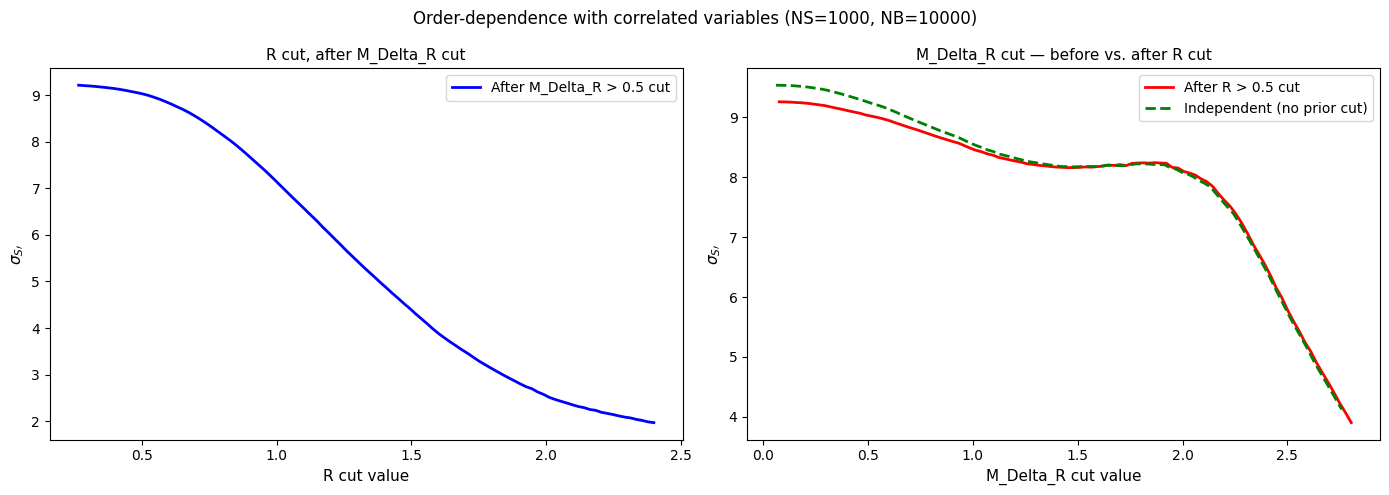

Note: when the prior cut removes many correlated events, the optimal
cut value and maximum significance can change significantly.


In [31]:
# Demonstrate order-dependence with correlated variables M_Delta_R and R
NS, NB = 1000, 10000

# Order 1: M_Delta_R first, then optimize R
xc_MDR = 0.5  # fixed cut on M_Delta_R
mask_s1 = apply_cut(df_sig, "M_Delta_R", "gt", xc_MDR)
mask_b1 = apply_cut(df_bkg, "M_Delta_R", "gt", xc_MDR)
sig_after1 = df_sig[mask_s1]
bkg_after1 = df_bkg[mask_b1]

# Compute significance of R cut after M_Delta_R cut
cut_vals_R, tpr_R_after, fpr_R_after = compute_efficiencies(
    np.array(sig_after1["R"]),
    np.array(bkg_after1["R"]),
    "gt"
)
# Adjust efficiencies to be relative to original sample
eps_s_MDR = len(sig_after1) / len(df_sig)
eps_b_MDR = len(bkg_after1) / len(df_bkg)
tpr_total1 = tpr_R_after * eps_s_MDR
fpr_total1 = fpr_R_after * eps_b_MDR
sig_order1 = significance(tpr_total1, fpr_total1, NS, NB)

# Order 2: R first, then optimize M_Delta_R
xc_R = 0.5  # fixed cut on R
mask_s2 = apply_cut(df_sig, "R", "gt", xc_R)
mask_b2 = apply_cut(df_bkg, "R", "gt", xc_R)
sig_after2 = df_sig[mask_s2]
bkg_after2 = df_bkg[mask_b2]

cut_vals_MDR, tpr_MDR_after, fpr_MDR_after = compute_efficiencies(
    np.array(sig_after2["M_Delta_R"]),
    np.array(bkg_after2["M_Delta_R"]),
    "gt"
)
eps_s_R = len(sig_after2) / len(df_sig)
eps_b_R = len(bkg_after2) / len(df_bkg)
tpr_total2 = tpr_MDR_after * eps_s_R
fpr_total2 = fpr_MDR_after * eps_b_R
sig_order2 = significance(tpr_total2, fpr_total2, NS, NB)

# Independent optimization (no prior cut)
cut_vals_MDR_ind, tpr_MDR_ind, fpr_MDR_ind = compute_efficiencies(
    np.array(df_sig["M_Delta_R"]), np.array(df_bkg["M_Delta_R"]), "gt"
)
sig_MDR_ind = significance(tpr_MDR_ind, fpr_MDR_ind, NS, NB)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(cut_vals_R, sig_order1, 'b-', label='After M_Delta_R > 0.5 cut', linewidth=2)
ax1.set_xlabel('R cut value', fontsize=11)
ax1.set_ylabel(r'$\sigma_{S\prime}$', fontsize=11)
ax1.set_title('R cut, after M_Delta_R cut', fontsize=11)
ax1.legend()

ax2.plot(cut_vals_MDR, sig_order2, 'r-', label='After R > 0.5 cut', linewidth=2)
ax2.plot(cut_vals_MDR_ind, sig_MDR_ind, 'g--', label='Independent (no prior cut)', linewidth=2)
ax2.set_xlabel('M_Delta_R cut value', fontsize=11)
ax2.set_ylabel(r'$\sigma_{S\prime}$', fontsize=11)
ax2.set_title('M_Delta_R cut — before vs. after R cut', fontsize=11)
ax2.legend()

fig.suptitle(f'Order-dependence with correlated variables ({NS=}, {NB=})', fontsize=12)
plt.tight_layout()
plt.show()

print("Note: when the prior cut removes many correlated events, the optimal")
print("cut value and maximum significance can change significantly.")

## Exercise 7: ROC Curves

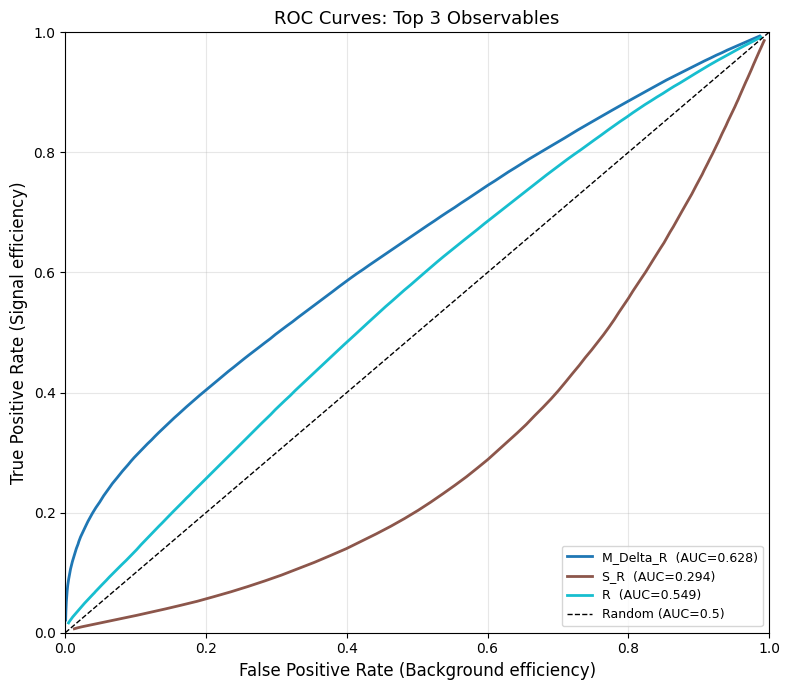

In [38]:
def plot_roc_curves(df_s, df_b, var_list, strategies, title="ROC Curves", ax=None, label_suffix=""):
    """
    Plot ROC curves for multiple variables on the same axes.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 7))
        show_plot = True
    else:
        show_plot = False

    colors = plt.cm.tab10(np.linspace(0, 1, len(var_list)))

    for var, color in zip(var_list, colors):
        strategy = strategies.get(var, "gt")
        fpr, tpr, auc = compute_roc(
            np.array(df_s[var]),
            np.array(df_b[var]),
            strategy
        )
        
        plot_label = f'{var} {label_suffix} (AUC={auc:.3f})'
        ax.plot(fpr, tpr, color=color, linewidth=2, label=plot_label)

    # Random classifier line
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.5)')

    ax.set_xlabel('False Positive Rate (Background efficiency)', fontsize=12)
    ax.set_ylabel('True Positive Rate (Signal efficiency)', fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=9, loc='lower right')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.grid(True, alpha=0.3)
    
    if show_plot:
        plt.tight_layout()
        plt.show()

# Exercise 7.1: Top 3 observables
top3_vars = ["M_Delta_R", "S_R", "R"]
plot_roc_curves(df_sig, df_bkg, top3_vars, selection_strategy, title="ROC Curves: Top 3 Observables")

ROC curves after successive cuts:


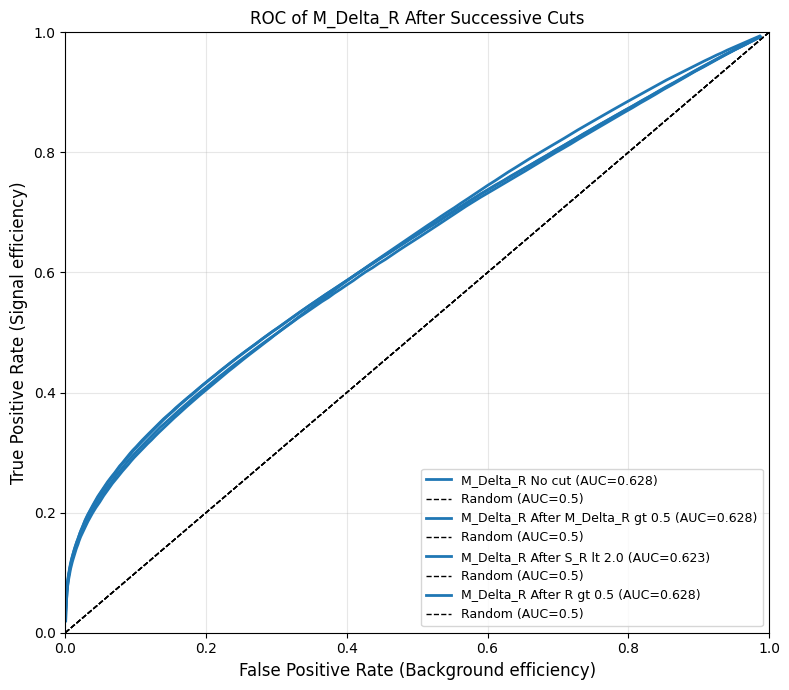

In [39]:
# Exercise 7.3: ROC curves after successive cuts
print("ROC curves after successive cuts:")

datasets = [
    ("No cut", df_sig, df_bkg),
]

current_sig = df_sig.copy()
current_bkg = df_bkg.copy()

for var, strategy, xc in cuts:
    mask_s = apply_cut(current_sig, var, strategy, xc)
    mask_b = apply_cut(current_bkg, var, strategy, xc)
    current_sig = current_sig[mask_s]
    current_bkg = current_bkg[mask_b]
    label = f"After {var} {strategy} {xc}"
    datasets.append((label, current_sig.copy(), current_bkg.copy()))

# Plot ROC curve for M_Delta_R after each successive cut
fig, ax = plt.subplots(figsize=(8, 7))

for label, current_sig, current_bkg in datasets:
    # Using the 7.2 function for each successive cut dataset
    plot_roc_curves(
        current_sig, 
        current_bkg, 
        var_list=["M_Delta_R"], 
        strategies=selection_strategy, 
        ax=ax, 
        label_suffix=label
    )

ax.set_title("ROC of M_Delta_R After Successive Cuts", fontsize=12)
plt.tight_layout()
plt.show()

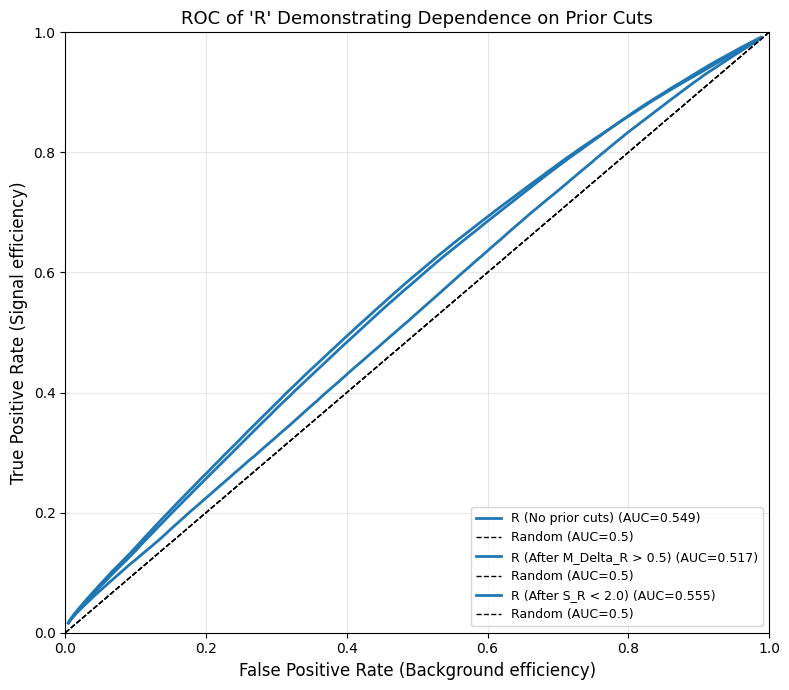

'Conclusion: While applying fixed boolean cuts in any order yields the same final event count,the ROC curve (and AUC) for a specific variable changes drastically depending on prior cuts.Because the variables are correlated, cutting one physically alters the distributions of the others,meaning the order in which you evaluate and optimize cuts absolutely matters.'

In [45]:
# Exercise 7.4: Order-dependence of successive cuts

# Set up the figure using our revised function capabilities
fig, ax = plt.subplots(figsize=(8, 7))

# Scenario 1: Baseline ROC for 'R' (No prior cuts)
plot_roc_curves(
    df_sig, 
    df_bkg, 
    var_list=["R"], 
    strategies={"R": "gt"}, 
    ax=ax, 
    label_suffix="(No prior cuts)"
)

# Scenario 2: Apply a cut on 'M_Delta_R' first, then look at 'R'
mask_s_MDR = apply_cut(df_sig, "M_Delta_R", "gt", 0.5)
mask_b_MDR = apply_cut(df_bkg, "M_Delta_R", "gt", 0.5)

sig_after_MDR = df_sig[mask_s_MDR]
bkg_after_MDR = df_bkg[mask_b_MDR]

plot_roc_curves(
    sig_after_MDR, 
    bkg_after_MDR, 
    var_list=["R"], 
    strategies={"R": "gt"}, 
    ax=ax, 
    label_suffix="(After M_Delta_R > 0.5)"
)

# Scenario 3: Apply a cut on 'S_R' first, then look at 'R'
mask_s_SR = apply_cut(df_sig, "S_R", "lt", 2.0)
mask_b_SR = apply_cut(df_bkg, "S_R", "lt", 2.0)

sig_after_SR = df_sig[mask_s_SR]
bkg_after_SR = df_bkg[mask_b_SR]

plot_roc_curves(
    sig_after_SR, 
    bkg_after_SR, 
    var_list=["R"], 
    strategies={"R": "gt"}, 
    ax=ax, 
    label_suffix="(After S_R < 2.0)"
)

# Format and display
ax.set_title("ROC of 'R' Demonstrating Dependence on Prior Cuts", fontsize=13)
plt.tight_layout()
plt.show()

# The scientific takeaway
"""Conclusion: While applying fixed boolean cuts in any order yields the same final event count,the ROC curve (and AUC) for a specific variable changes drastically depending on prior cuts.Because the variables are correlated, cutting one physically alters the distributions of the others,meaning the order in which you evaluate and optimize cuts absolutely matters."""

## Exercise 8: Linear Discriminant (Fisher's)

In [46]:
# Exercise 8.1: Compute S_B and S_W

# Use all 18 observable variables
obs_vars = VarNames[1:]  # exclude 'signal'

X_sig = np.array(df_sig[obs_vars], dtype=float)
X_bkg = np.array(df_bkg[obs_vars], dtype=float)

m1 = X_sig.mean(axis=0)  # signal mean
m2 = X_bkg.mean(axis=0)  # background mean

diff = (m2 - m1).reshape(-1, 1)
S_B = diff @ diff.T  # between-class scatter

# Within-class scatter
def within_class_scatter(X, m):
    """Compute within-class scatter matrix for class with mean m."""
    X_centered = X - m
    return X_centered.T @ X_centered

S_W = within_class_scatter(X_sig, m1) + within_class_scatter(X_bkg, m2)

print(f"S_B shape: {S_B.shape}")
print(f"S_W shape: {S_W.shape}")
print(f"S_B max value: {np.max(np.abs(S_B)):.3e}")
print(f"S_W max value: {np.max(np.abs(S_W)):.3e}")

S_B shape: (18, 18)
S_W shape: (18, 18)
S_B max value: 5.936e-01
S_W max value: 5.031e+05


In [ ]:
# Exercise 8.2: Compute linear weights w and discriminant F

# w = S_W^{-1} (m2 - m1)
# Calculating the inverse explicitly just like the formula
S_W_inv = np.linalg.inv(S_W)
w = S_W_inv @ (m2 - m1)

print(f"Weight vector w shape: {w.shape}")
print("Weights:")
for var, wi in zip(obs_vars, w):
    print(f"  {var:15s}: {wi:.4f}")

# Compute discriminant score F = w^T x for each event
F_sig = X_sig @ w
F_bkg = X_bkg @ w

# Plot distributions
fig, ax = plt.subplots(figsize=(9, 5))

# Standard student binning
bins = 50

ax.hist(F_sig, bins=bins, density=True, histtype='step', color='red', linewidth=2, label='Signal')
ax.hist(F_bkg, bins=bins, density=True, histtype='step', color='blue', linewidth=2, label='Background')

ax.set_xlabel("Fisher discriminant $F = \\mathbf{w}^T \\mathbf{x}$", fontsize=12)
ax.set_ylabel("Normalized counts", fontsize=12)
ax.set_title("Fisher Linear Discriminant", fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# Exercise 8.3: ROC curve for Fisher discriminant
# Compare with top individual variables

fpr_F, tpr_F, auc_F = compute_roc(F_sig, F_bkg, strategy="gt")

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(fpr_F, tpr_F, 'k-', linewidth=2.5, label=f'Fisher LDA (AUC={auc_F:.3f})')

# Overlay top 3 individual variable ROC curves
colors = ['red', 'blue', 'green']
for var, color in zip(top3_vars, colors):
    strategy = selection_strategy.get(var, "gt")
    fpr, tpr, auc = compute_roc(
        np.array(df_sig[var]),
        np.array(df_bkg[var]),
        strategy
    )
    ax.plot(fpr, tpr, color=color, linewidth=1.5,
            linestyle='--', label=f'{var} (AUC={auc:.3f})')

ax.plot([0, 1], [0, 1], 'gray', linestyle=':', linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves: Fisher LDA vs. Individual Variables', fontsize=12)
ax.legend(fontsize=10, loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Fisher LDA AUC: {auc_F:.4f}")
print("Fisher LDA combines all variables and achieves better AUC than any single variable.")

In [ ]:
# Exercise 8.4: Maximum significance with Fisher discriminant

print("Maximum significance achievable with Fisher discriminant:\n")

# Get efficiencies for all cut values
cut_vals_F, tpr_array, fpr_array = compute_efficiencies(F_sig, F_bkg, "gt", n_cuts=300)

for NS, NB, label in scenarios:
    sig_array = significance(tpr_array, fpr_array, NS, NB)
    max_sig = np.max(sig_array)
    best_cut = cut_vals_F[np.argmax(sig_array)]
    print(f"  {label}:")
    print(f"    Max significance = {max_sig:.3f} (at F > {best_cut:.3f})")
    print(f"    eps_S = {tpr_array[np.argmax(sig_array)]:.3f}, "
          f"eps_B = {fpr_array[np.argmax(sig_array)]:.4f}")
    print()